# Crop Yield Prediction based

### Shreeya Tapaswi

`About the Dataset`

Link- https://www.kaggle.com/datasets/anshumish/crop-yield-data-with-soil-and-weather-dataset

This dataset collection combines crop yields, soil composition, and weather data across Indian states, providing a comprehensive view of agriculture between 1997 and 2020. It includes:

Crop Yield Data: Crop-wise area, production, fertilizer/pesticide use, and yield trends.

Soil Data: State-level soil nutrients (N, P, K) and pH values.

Weather Data: Annual averages of temperature, rainfall, and humidity.

By integrating these datasets, users can explore how soil health, climatic conditions, and farm inputs interact to influence agricultural productivity.

## 1. Setup and Library Imports

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

### 2. Data Loading

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving crop_yield.csv to crop_yield.csv
Saving state_soil_data.csv to state_soil_data.csv
Saving state_weather_data_1997_2020.csv to state_weather_data_1997_2020.csv


#### Load Datasets

In [ ]:
crop = pd.read_csv("crop_yield.csv")
soil = pd.read_csv("state_soil_data.csv")
weather = pd.read_csv("state_weather_data_1997_2020.csv")

print("Crop Dataset Shape:", crop.shape)
print("Soil Dataset Shape:", soil.shape)
print("Weather Dataset Shape:", weather.shape)

Crop Dataset Shape: (19689, 9)
Soil Dataset Shape: (30, 5)
Weather Dataset Shape: (720, 5)


#### Initial Data Inspection - Head

In [ ]:
print("CROP DATA")
display(crop.head())

print("\nSOIL DATA")
display(soil.head())

print("\nWEATHER DATA")
display(weather.head())

CROP DATA


,crop,year,season,state,area,production,fertilizer,pesticide,yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909



SOIL DATA


,state,N,P,K,pH
0,Andhra Pradesh,78,45,22,6.8
1,Arunachal Pradesh,55,15,35,5.5
2,Assam,60,18,38,5.8
3,Bihar,85,30,25,7.2
4,Chhattisgarh,70,35,20,6.5



WEATHER DATA


,state,year,avg_temp_c,total_rainfall_mm,avg_humidity_percent
0,Andhra Pradesh,1997,28.21,1191.08,69.56
1,Andhra Pradesh,1998,28.21,1100.41,71.95
2,Andhra Pradesh,1999,28.03,603.67,66.91
3,Andhra Pradesh,2000,27.74,1070.25,70.73
4,Andhra Pradesh,2001,28.08,910.13,68.69


#### Initial Data Inspection - Info

In [ ]:
print("========== CROP DATA ==========")
crop.info()

print("\n========== SOIL DATA ==========")
soil.info()

print("\n========== WEATHER DATA ==========")
weather.info()

========== CROP DATA ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   crop        19689 non-null  object 
 1   year        19689 non-null  int64  
 2   season      19689 non-null  object 
 3   state       19689 non-null  object 
 4   area        19689 non-null  float64
 5   production  19689 non-null  int64  
 6   fertilizer  19689 non-null  float64
 7   pesticide   19689 non-null  float64
 8   yield       19689 non-null  float64
dtypes: float64(4), int64(2), object(3)
memory usage: 1.4+ MB

========== SOIL DATA ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   state   30 non-null     object 
 1   N       30 non-null     int64  
 2   P       30 non-null     int64  
 3   K       30 non-null   

## 3. Data Cleaning and Preprocessing

In [ ]:
crop.columns = crop.columns.str.strip().str.lower()
soil.columns = soil.columns.str.strip().str.lower()
weather.columns = weather.columns.str.strip().str.lower()

print(crop.columns)
print(soil.columns)
print(weather.columns)

Index(['crop', 'year', 'season', 'state', 'area', 'production', 'fertilizer',
       'pesticide', 'yield'],
      dtype='object')
Index(['state', 'n', 'p', 'k', 'ph'], dtype='object')
Index(['state', 'year', 'avg_temp_c', 'total_rainfall_mm',
       'avg_humidity_percent'],
      dtype='object')


### Standardize Column Names

In [ ]:
# Remove unnecessary spaces from categorical columns

for df in [crop, soil, weather]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].astype(str).str.strip()

print("String cleaning completed.")

String cleaning completed.


### Clean Categorical String Data

### Verify Data Types After String Cleaning

In [ ]:
print("Crop Dataset Data Types:")
display(crop.dtypes)

print("\nSoil Dataset Data Types:")
display(soil.dtypes)

print("\nWeather Dataset Data Types:")
display(weather.dtypes)

Crop Dataset Data Types:


,0
crop,object
year,int64
season,object
state,object
area,float64
production,int64
fertilizer,float64
pesticide,float64
yield,float64



Soil Dataset Data Types:


,0
state,object
n,int64
p,int64
k,int64
ph,float64



Weather Dataset Data Types:


,0
state,object
year,int64
avg_temp_c,float64
total_rainfall_mm,float64
avg_humidity_percent,float64


### Ensure 'year' Columns are Numeric

In [ ]:
crop["year"] = pd.to_numeric(crop["year"], errors="coerce").astype("Int64")
weather["year"] = pd.to_numeric(weather["year"], errors="coerce").astype("Int64")

After initial data loading, we check for missing values across all datasets. The output here confirms the counts of missing values per column. Subsequent steps will address these through imputation or removal, as necessary.

### Missing Values Analysis

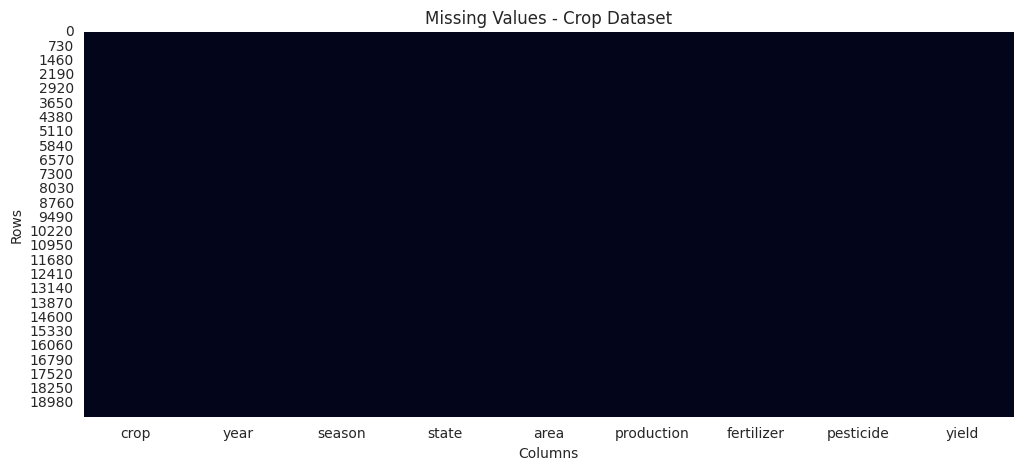

In [ ]:
plt.figure(figsize=(12, 5))

sns.heatmap(crop.isnull(), cbar=False)

plt.title("Missing Values - Crop Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

This heatmap visually represents the missing values in the Crop dataset.
The absence of color indicates no missing data, confirming the dataset's completeness.

#### Visualize Missing Values - Crop Dataset

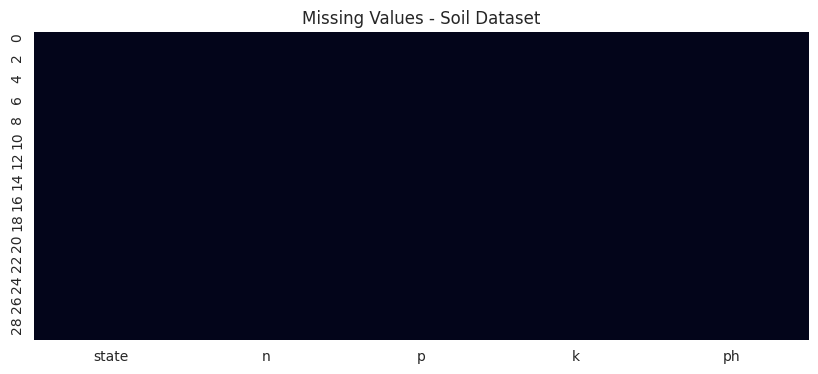

In [ ]:
plt.figure(figsize=(10, 4))

sns.heatmap(soil.isnull(), cbar=False)

plt.title("Missing Values - Soil Dataset")
plt.show()

This heatmap shows the missing values in the Soil dataset.
A uniform colored map indicates no missing data, confirming its completeness.

#### Visualize Missing Values - Soil Dataset

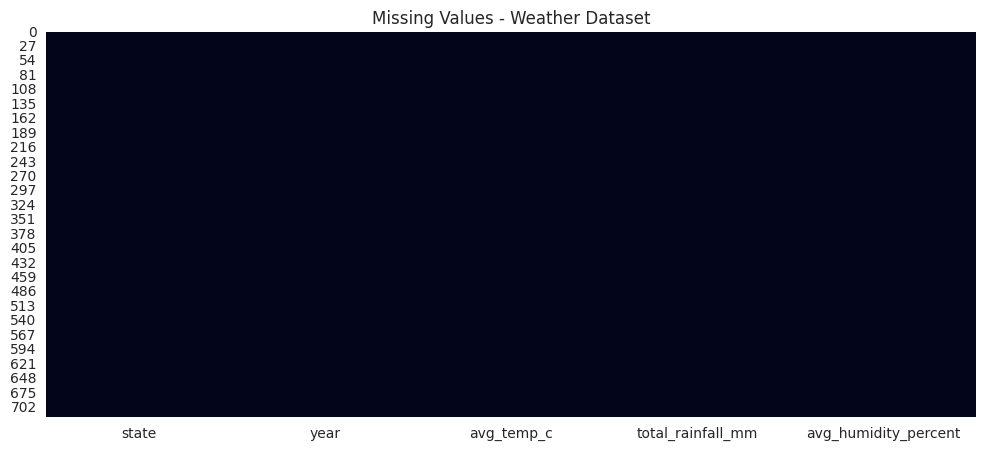

In [ ]:
plt.figure(figsize=(12, 5))

sns.heatmap(weather.isnull(), cbar=False)

plt.title("Missing Values - Weather Dataset")
plt.show()

This heatmap illustrates the missing values in the Weather dataset.
The consistent coloring suggests no missing entries, affirming the dataset's integrity.

#### Visualize Missing Values - Weather Dataset

In [ ]:
for df in [crop, soil, weather]:
    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

### Impute Missing Values

In [ ]:
for df in [crop, soil, weather]:
    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:
        df[col] = df[col].fillna(df[col].median())

#### Impute Missing Numeric Values with Median

In [ ]:
for df in [crop, soil, weather]:
    categorical_cols = df.select_dtypes(include="object").columns

    for col in categorical_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mode()[0])

#### Impute Missing Categorical Values with Mode

In [ ]:
print("Duplicate rows in Crop:", crop.duplicated().sum())
print("Duplicate rows in Soil:", soil.duplicated().sum())
print("Duplicate rows in Weather:", weather.duplicated().sum())

Duplicate rows in Crop: 0
Duplicate rows in Soil: 0
Duplicate rows in Weather: 0


### Duplicate Record Analysis

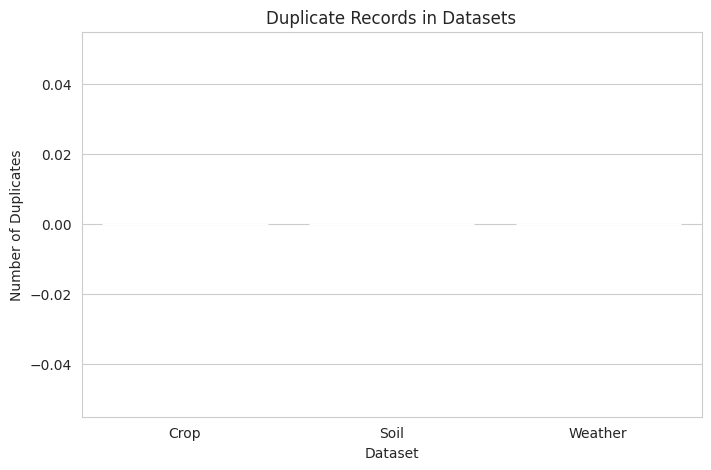

In [ ]:
duplicate_counts = {
    "Crop": crop.duplicated().sum(),
    "Soil": soil.duplicated().sum(),
    "Weather": weather.duplicated().sum()
}

plt.figure(figsize=(8, 5))

sns.barplot(
    x=list(duplicate_counts.keys()),
    y=list(duplicate_counts.values())
)

plt.title("Duplicate Records in Datasets")
plt.xlabel("Dataset")
plt.ylabel("Number of Duplicates")
plt.show()

This bar chart visualizes the number of duplicate records across the Crop, Soil, and Weather datasets.
All datasets show zero duplicates, confirming the removal of redundant entries.

#### Visualize Duplicate Counts

In [ ]:
crop = crop.drop_duplicates().reset_index(drop=True)
soil = soil.drop_duplicates().reset_index(drop=True)
weather = weather.drop_duplicates().reset_index(drop=True)

print("Duplicates removed.")

Duplicates removed.


### Remove Duplicate Rows

In [ ]:
print(
    "Duplicate State-Year records in Weather:",
    weather.duplicated(subset=["state", "year"]).sum()
)

Duplicate State-Year records in Weather: 0


### Check for Specific Duplicates (State-Year in Weather)

In [ ]:
weather = weather.drop_duplicates(
    subset=["state", "year"]
).reset_index(drop=True)

### Check for Duplicate States in Soil

In [ ]:
print(
    "Duplicate states in Soil:",
    soil["state"].duplicated().sum()
)

Duplicate states in Soil: 0


### Ensure State Consistency Across Datasets

In [ ]:
print("Crop states:", crop["state"].nunique())
print("Soil states:", soil["state"].nunique())
print("Weather states:", weather["state"].nunique())

Crop states: 30
Soil states: 30
Weather states: 30


## 4. Data Merging

In [ ]:
crop_states = set(crop["state"].unique())
soil_states = set(soil["state"].unique())
weather_states = set(weather["state"].unique())

print("States missing from Soil:")
print(crop_states - soil_states)

print("\nStates missing from Weather:")
print(crop_states - weather_states)

States missing from Soil:
set()

States missing from Weather:
set()


### Merge Crop with Soil Data

In [ ]:
df = pd.merge(
    crop,
    soil,
    on="state",
    how="left"
)

print("Shape after Crop + Soil merge:", df.shape)
display(df.head())

Shape after Crop + Soil merge: (19689, 13)


,crop,year,season,state,area,production,fertilizer,pesticide,yield,n,p,k,ph
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087,60,18,38,5.8
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435,60,18,38,5.8
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333,60,18,38,5.8
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,1870661.52,6093.36,5238.051739,60,18,38,5.8
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909,60,18,38,5.8


### Merge with Weather Data

In [ ]:
df = pd.merge(
    df,
    weather,
    on=["state", "year"],
    how="left"
)

print("Final Dataset Shape:", df.shape)

display(df.head())

Final Dataset Shape: (19689, 16)


,crop,year,season,state,area,production,fertilizer,pesticide,yield,n,p,k,ph,avg_temp_c,total_rainfall_mm,avg_humidity_percent
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,7024878.38,22882.34,0.796087,60,18,38,5.8,22.41,1468.92,70.71
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,631643.29,2057.47,0.710435,60,18,38,5.8,22.41,1468.92,70.71
2,Castor seed,1997,Kharif,Assam,796.0,22,75755.32,246.76,0.238333,60,18,38,5.8,22.41,1468.92,70.71
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,1870661.52,6093.36,5238.051739,60,18,38,5.8,22.41,1468.92,70.71
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,165500.63,539.09,0.420909,60,18,38,5.8,22.41,1468.92,70.71


### Check for Missing Values After Merging

In [ ]:
print("Final columns:")

for i, col in enumerate(df.columns, 1):
    print(i, ".", col)

Final columns:
1 . crop
2 . year
3 . season
4 . state
5 . area
6 . production
7 . fertilizer
8 . pesticide
9 . yield
10 . n
11 . p
12 . k
13 . ph
14 . avg_temp_c
15 . total_rainfall_mm
16 . avg_humidity_percent


### Impute Remaining Missing Values (Post-Merge)

In [ ]:
missing = df.isnull().sum()

print("Missing values after merging:")
display(missing[missing > 0])

Missing values after merging:


,0


### Verify No Missing Values Remain

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

## 5. Exploratory Data Analysis (EDA)

In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### Overview of Merged Dataset

In [ ]:
df.shape

(19689, 16)

#### Basic Statistics and Information

In [ ]:
df.describe()

,year,area,production,fertilizer,pesticide,yield,n,p,k,ph,avg_temp_c,total_rainfall_mm,avg_humidity_percent
count,19689.0,1.968900e+04,1.968900e+04,1.968900e+04,1.968900e+04,19689.000000,19689.000000,19689.000000,19689.000000,19689.000000,19689.000000,19689.000000,19689.000000
mean,2009.127584,1.799266e+05,1.643594e+07,2.410331e+07,4.884835e+04,79.954009,76.626847,33.499264,32.234547,6.640292,24.008025,1337.999356,64.676018
std,6.498099,7.328287e+05,2.630568e+08,9.494600e+07,2.132874e+05,878.306193,20.060556,11.556686,7.915514,0.690622,4.408018,637.585197,11.474130
min,1997.0,5.000000e-01,0.000000e+00,5.417000e+01,9.000000e-02,0.000000,50.000000,15.000000,20.000000,5.500000,6.260000,249.240000,34.470000
25%,2004.0,1.390000e+03,1.393000e+03,1.880146e+05,3.567000e+02,0.600000,65.000000,24.000000,25.000000,6.000000,22.910000,894.160000,54.620000
50%,2010.0,9.317000e+03,1.380400e+04,1.234957e+06,2.421900e+03,1.030000,72.000000,38.000000,33.000000,6.600000,25.560000,1172.020000,68.110000
75%,2015.0,7.511200e+04,1.227180e+05,1.000385e+07,2.004170e+04,2.388889,80.000000,43.000000,38.000000,7.100000,26.810000,1613.400000,73.730000
max,2020.0,5.080810e+07,6.326000e+09,4.835407e+09,1.575051e+07,21105.000000,150.000000,55.000000,50.000000,8.000000,28.630000,5244.360000,86.060000


The `df.describe()` output from the previous cell provides key statistical summaries for numerical features like count, mean, std, min, max, and quartiles, giving a quick overview of data distribution and potential issues.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   crop                  19689 non-null  object 
 1   year                  19689 non-null  Int64  
 2   season                19689 non-null  object 
 3   state                 19689 non-null  object 
 4   area                  19689 non-null  float64
 5   production            19689 non-null  int64  
 6   fertilizer            19689 non-null  float64
 7   pesticide             19689 non-null  float64
 8   yield                 19689 non-null  float64
 9   n                     19689 non-null  int64  
 10  p                     19689 non-null  int64  
 11  k                     19689 non-null  int64  
 12  ph                    19689 non-null  float64
 13  avg_temp_c            19689 non-null  float64
 14  total_rainfall_mm     19689 non-null  float64
 15  avg_humidity_percen

The `df.info()` output (from the previous cell) is crucial for understanding the data types of each column and checking for non-null values. This helps confirm data integrity and proper loading.

In [ ]:
df.nunique()

,0
crop,55
year,24
season,6
state,30
area,13644
production,14016
fertilizer,18598
pesticide,17405
yield,13551
n,23


#### Basic Dataset Statistics

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Number of crops:", df["crop"].nunique())
print("Number of states:", df["state"].nunique())
print("Number of seasons:", df["season"].nunique())
print("Year range:", df["year"].min(), "-", df["year"].max())

Number of rows: 19689
Number of columns: 16
Number of crops: 55
Number of states: 30
Number of seasons: 6
Year range: 1997 - 2020


### EDA Observations Summary

From the initial Exploratory Data Analysis, several key insights have emerged:

*   **Dataset Overview:** The merged dataset (`df`) contains `19689` entries and `16` columns, covering various crops, years, seasons, states, and environmental factors. There are `55` unique crops, `30` states, and `6` seasons represented.

*   **Target Variable Distribution (`yield`):** The `yield` column shows a wide range of values, indicating variability in crop productivity. Initial inspection with `df.describe()` suggests a right-skewed distribution, which will be further analyzed and handled through outlier treatment.

*   **Feature Distribution:** Numerical features like `area`, `production`, `fertilizer`, and `pesticide` also exhibit wide ranges and potential outliers, which require careful handling to ensure robust model training.

*   **Missing Values:** After merging, we verified that there are no missing values remaining in the dataset, ensuring completeness for modeling.

*   **Duplicate Records:** All datasets (`crop`, `soil`, `weather`) were checked for duplicate rows, and none were found, ensuring data uniqueness.

*   **Top Crops:** The analysis revealed that 'Rice', 'Maize', 'Moong(Green Gram)', 'Urad', and 'Groundnut' are the most frequently recorded crops in the dataset. Focusing on these top 5 crops will allow for a more detailed analysis of their specific yield patterns.

These initial observations provide a solid foundation for further data cleaning, preprocessing, and model development.

### Top Crops Analysis

In [ ]:
crop_counts = df["crop"].value_counts()

display(crop_counts.head(20))

,count
crop,
Rice,1197
Maize,975
Moong(Green Gram),740
Urad,733
Groundnut,725
Sesamum,685
Potato,628
Sugarcane,605
Wheat,545


#### Visualize Top 15 Crops by Record Count

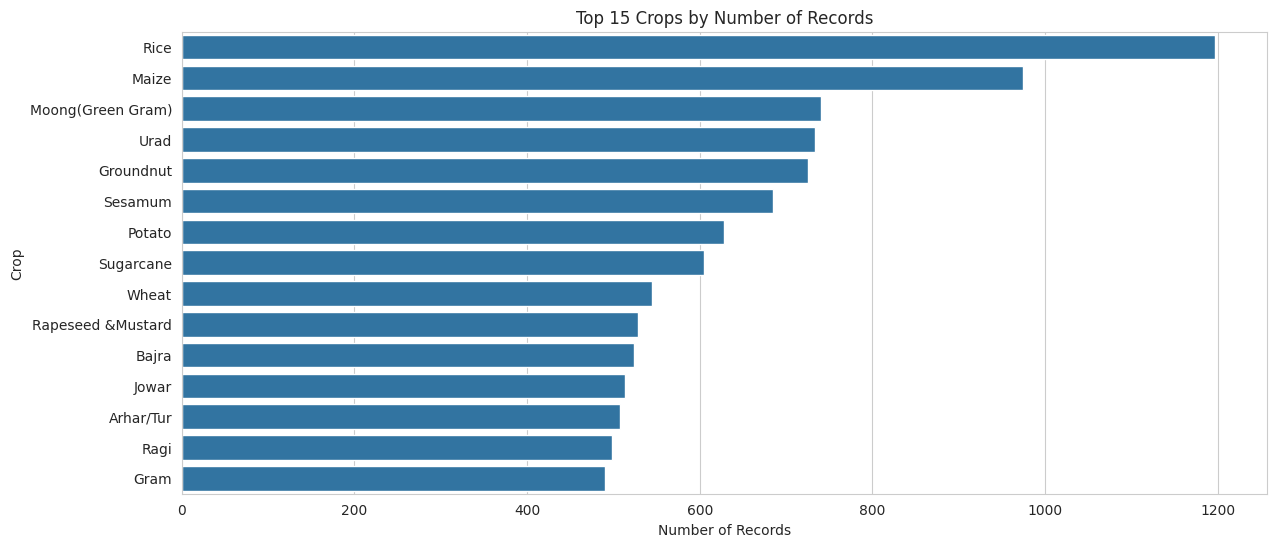

In [ ]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=crop_counts.head(15).values,
    y=crop_counts.head(15).index
)

plt.title("Top 15 Crops by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.show()

This chart highlights the top 15 crops based on the number of records.
Rice and Maize are the most frequently recorded crops in the dataset.

### Focus on Top 5 Crops

In [ ]:
top_5_crops = df["crop"].value_counts().head(5).index.tolist()

print("Top 5 Crops:")
for i, crop_name in enumerate(top_5_crops, 1):
    print(i, crop_name)

Top 5 Crops:
1 Rice
2 Maize
3 Moong(Green Gram)
4 Urad
5 Groundnut


#### Filter Dataset for Top 5 Crops

In [ ]:
df_top5 = df[df["crop"].isin(top_5_crops)].copy()

print("Original dataset:", df.shape)
print("Top 5 crop dataset:", df_top5.shape)

Original dataset: (19689, 16)
Top 5 crop dataset: (4370, 16)


#### Distribution of Top 5 Crops

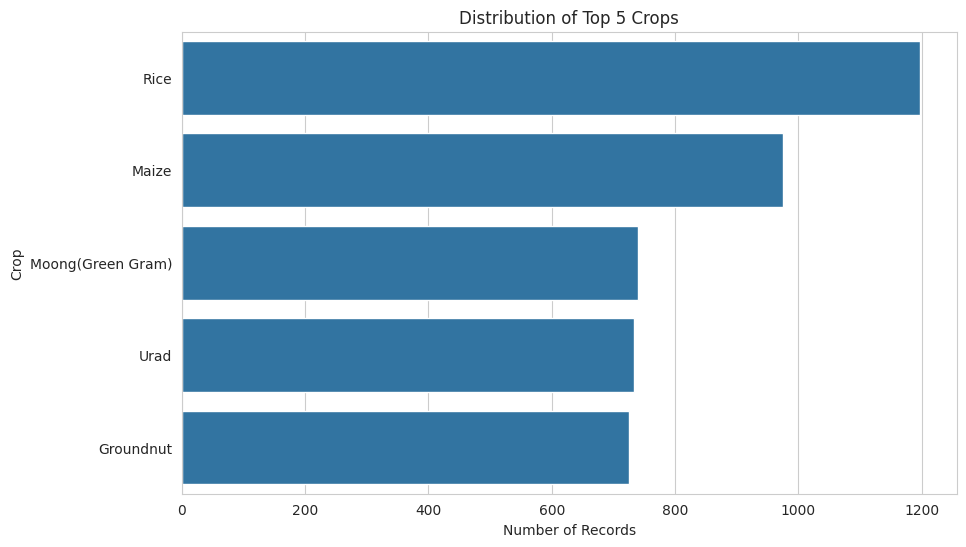

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_top5,
    y="crop",
    order=top_5_crops
)

plt.title("Distribution of Top 5 Crops")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.show()

This countplot displays the distribution of the top 5 crops, showing their relative frequencies.
Rice has the highest number of records among the top 5 crops.

### Analyze Yield Distribution

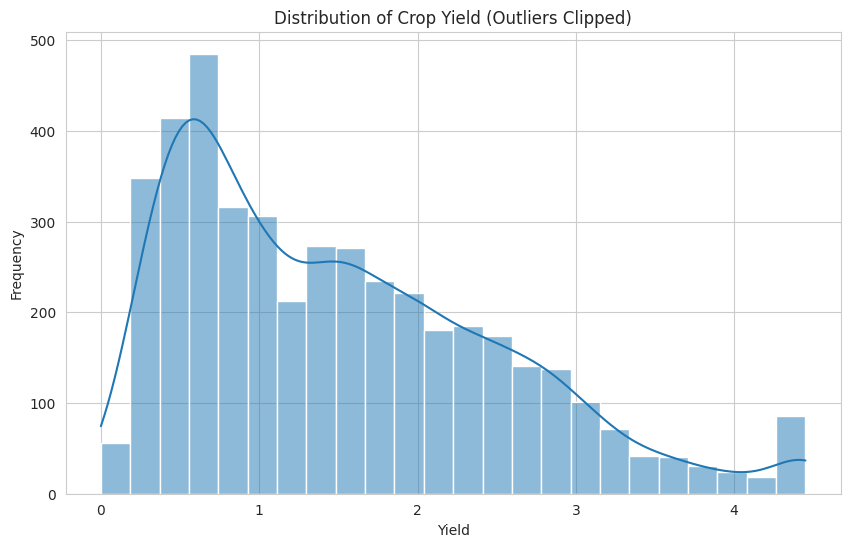

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(
    df_clean["yield"],
    kde=True
)
plt.title("Distribution of Crop Yield (Outliers Clipped)")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.show()

This histogram shows the distribution of crop yield after outlier clipping. The distribution is now more concentrated, revealing a clearer pattern with fewer extreme values.

#### Histogram of Crop Yield

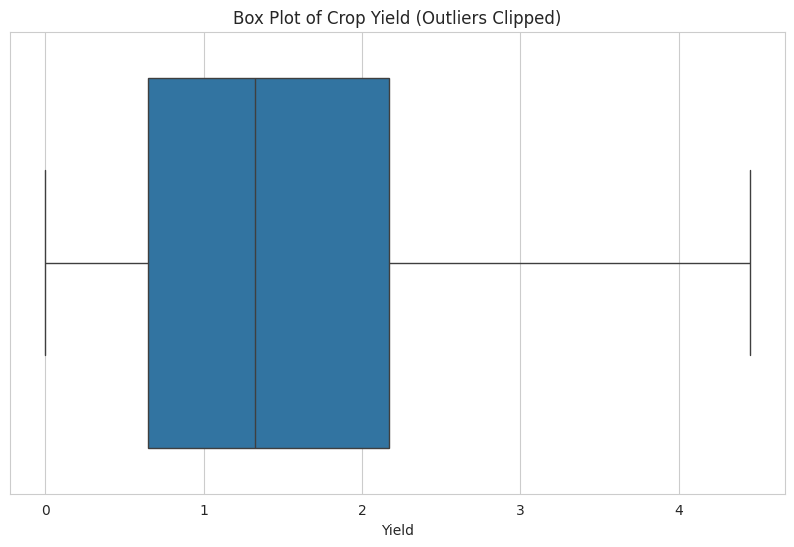

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean,
    x="yield"
)
plt.title("Box Plot of Crop Yield (Outliers Clipped)")
plt.xlabel("Yield")
plt.show()

This box plot illustrates the crop yield distribution after outlier clipping. The plot now shows a more representative spread of the data, with reduced influence from extreme outliers.

#### Box Plot of Crop Yield

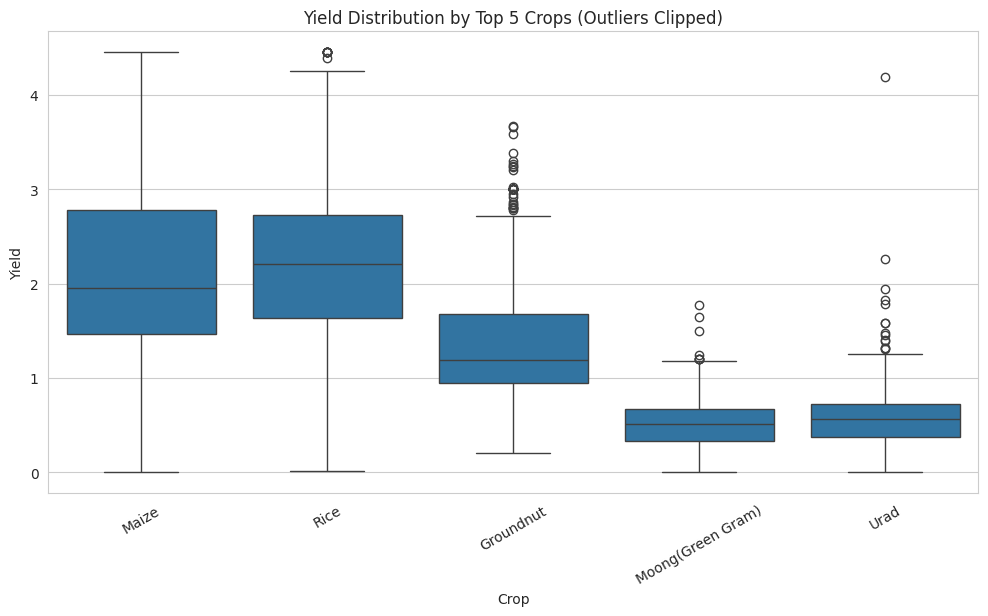

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_clean,
    x="crop",
    y="yield"
)
plt.title("Yield Distribution by Top 5 Crops (Outliers Clipped)")
plt.xlabel("Crop")
plt.ylabel("Yield")
plt.xticks(rotation=30)
plt.show()

This box plot compares the yield distribution across the top 5 crops after outlier clipping. The comparison between crops is clearer, showing differences in median yield and variability more accurately.

#### Yield Distribution by Top 5 Crops

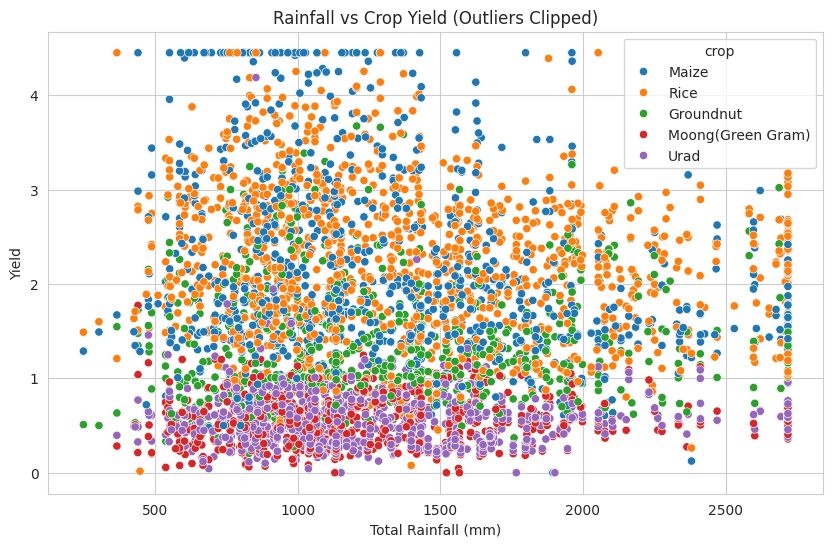

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="total_rainfall_mm",
    y="yield",
    hue="crop"
)
plt.title("Rainfall vs Crop Yield (Outliers Clipped)")
plt.xlabel("Total Rainfall (mm)")
plt.ylabel("Yield")
plt.show()

This scatter plot explores the relationship between total rainfall and crop yield for the top 5 crops after outlier clipping. The relationships are now more discernible, allowing for better identification of patterns.

### Yield vs. Environmental Factors

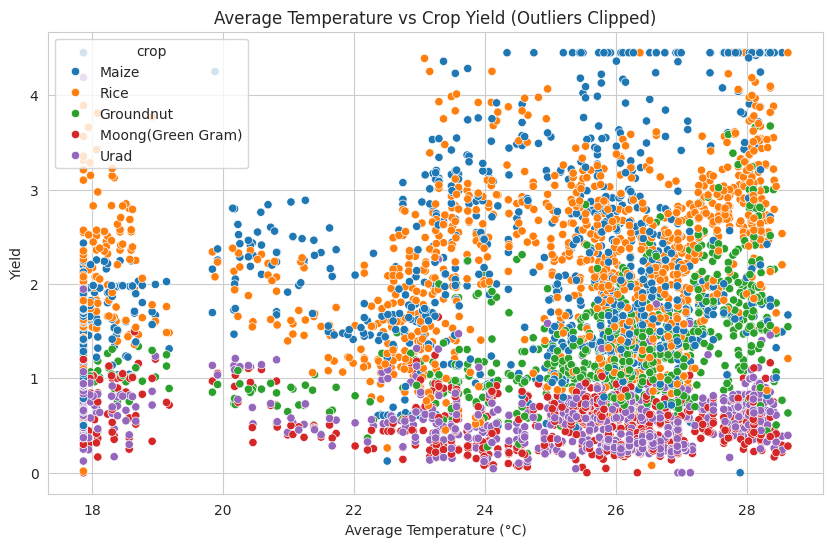

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="avg_temp_c",
    y="yield",
    hue="crop"
)
plt.title("Average Temperature vs Crop Yield (Outliers Clipped)")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Yield")
plt.show()

This scatter plot illustrates the relationship between average temperature and crop yield for the top 5 crops after outlier clipping. The clearer visualization helps in identifying any subtle correlations without distortion from extreme values.

#### Average Temperature vs Crop Yield

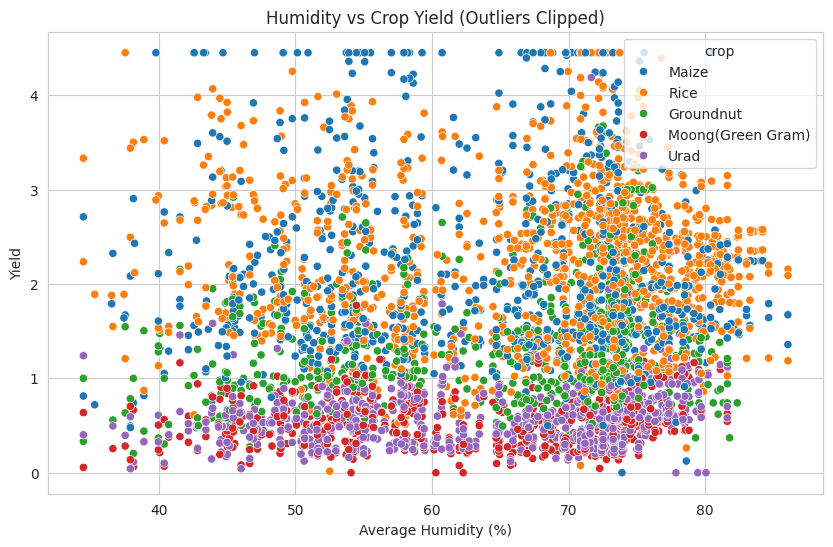

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="avg_humidity_percent",
    y="yield",
    hue="crop"
)
plt.title("Humidity vs Crop Yield (Outliers Clipped)")
plt.xlabel("Average Humidity (%)")
plt.ylabel("Yield")
plt.show()

This scatter plot shows the relationship between average humidity and crop yield for the top 5 crops after outlier clipping. The reduced scatter from extreme points makes it easier to observe any underlying trends.

#### Humidity vs Crop Yield

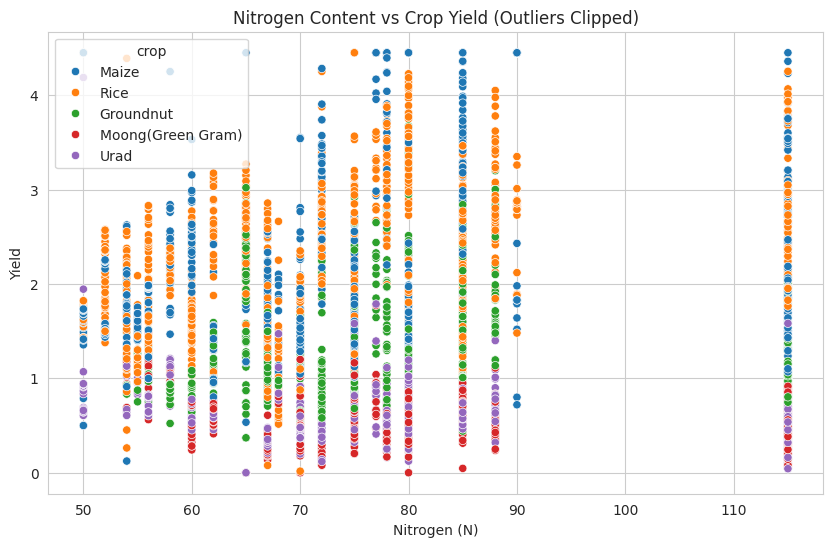

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="n",
    y="yield",
    hue="crop"
)
plt.title("Nitrogen Content vs Crop Yield (Outliers Clipped)")
plt.xlabel("Nitrogen (N)")
plt.ylabel("Yield")
plt.show()

This scatter plot examines the impact of Nitrogen (N) content on crop yield after outlier clipping. The concentrated data points allow for a more precise assessment of the relationship between nitrogen and yield.

### Yield vs. Soil Nutrients (N, P, K)

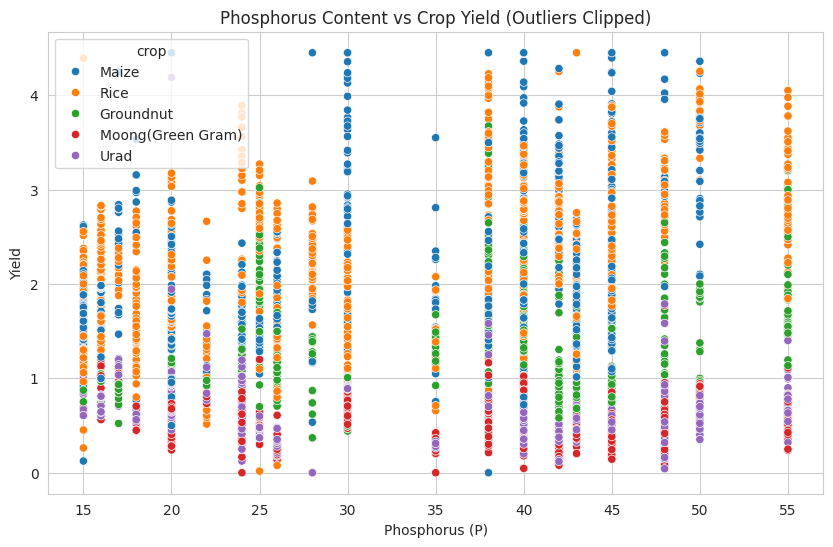

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="p",
    y="yield",
    hue="crop"
)
plt.title("Phosphorus Content vs Crop Yield (Outliers Clipped)")
plt.xlabel("Phosphorus (P)")
plt.ylabel("Yield")
plt.show()

This scatter plot visualizes the relationship between Phosphorus (P) content and crop yield after outlier clipping. The refined scale offers a clearer view of how phosphorus levels influence yield across different crops.

#### Phosphorus Content vs Crop Yield

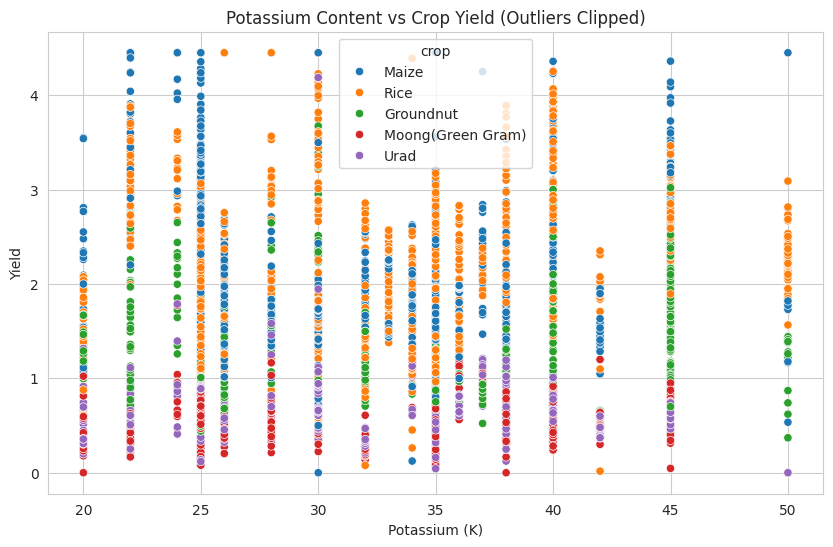

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="k",
    y="yield",
    hue="crop"
)
plt.title("Potassium Content vs Crop Yield (Outliers Clipped)")
plt.xlabel("Potassium (K)")
plt.ylabel("Yield")
plt.show()

This scatter plot explores the relationship between Potassium (K) content and crop yield after outlier clipping. With outliers removed, any potential trends or clusters related to potassium content and yield are more visible.

#### Potassium Content vs Crop Yield

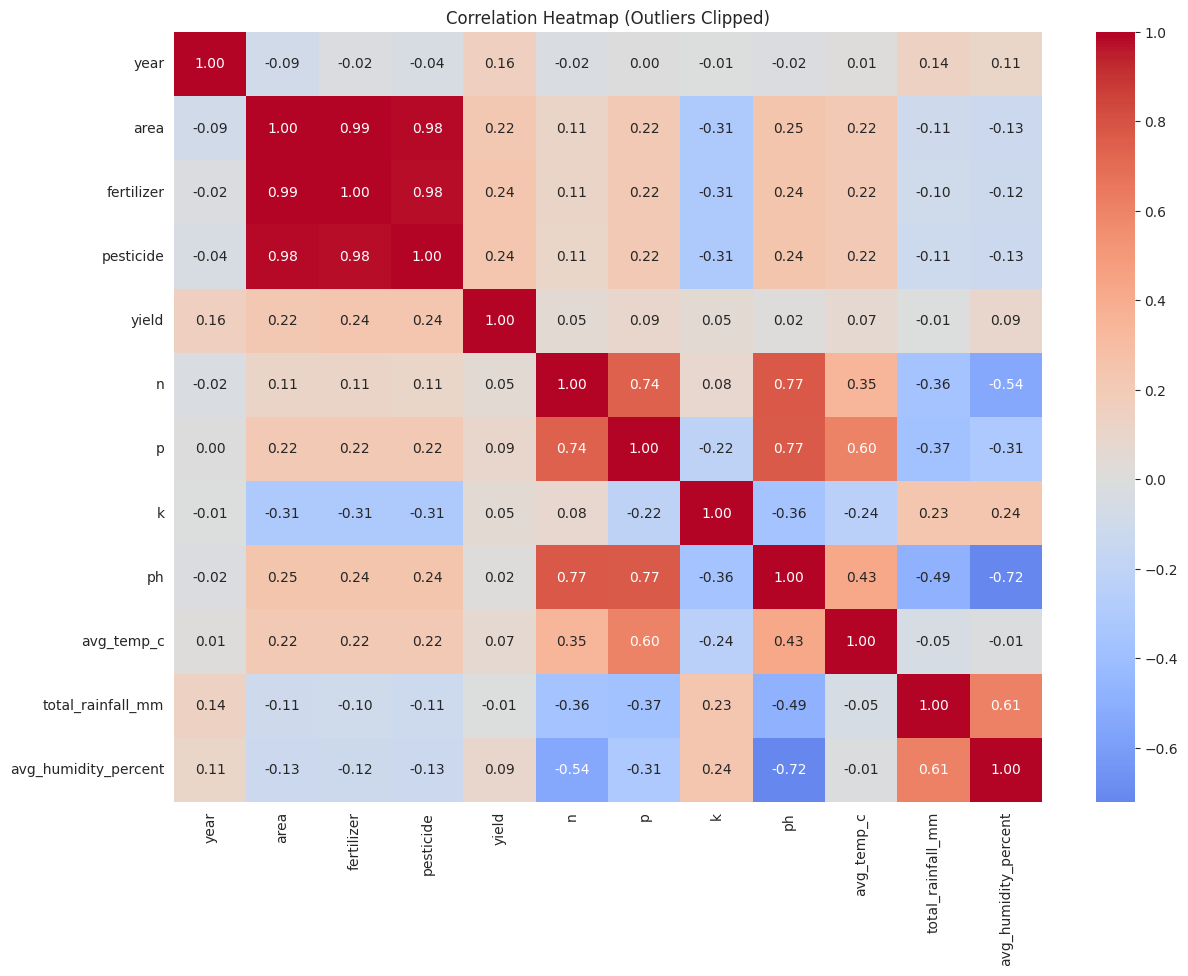

In [ ]:
numeric_data = df_clean.select_dtypes(include=np.number)
correlation = numeric_data.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap (Outliers Clipped)")
plt.show()

This heatmap displays the correlation matrix for numerical features after outlier clipping. The correlations are now calculated on a more robust dataset, potentially revealing truer relationships between variables.

### Feature Correlation Analysis

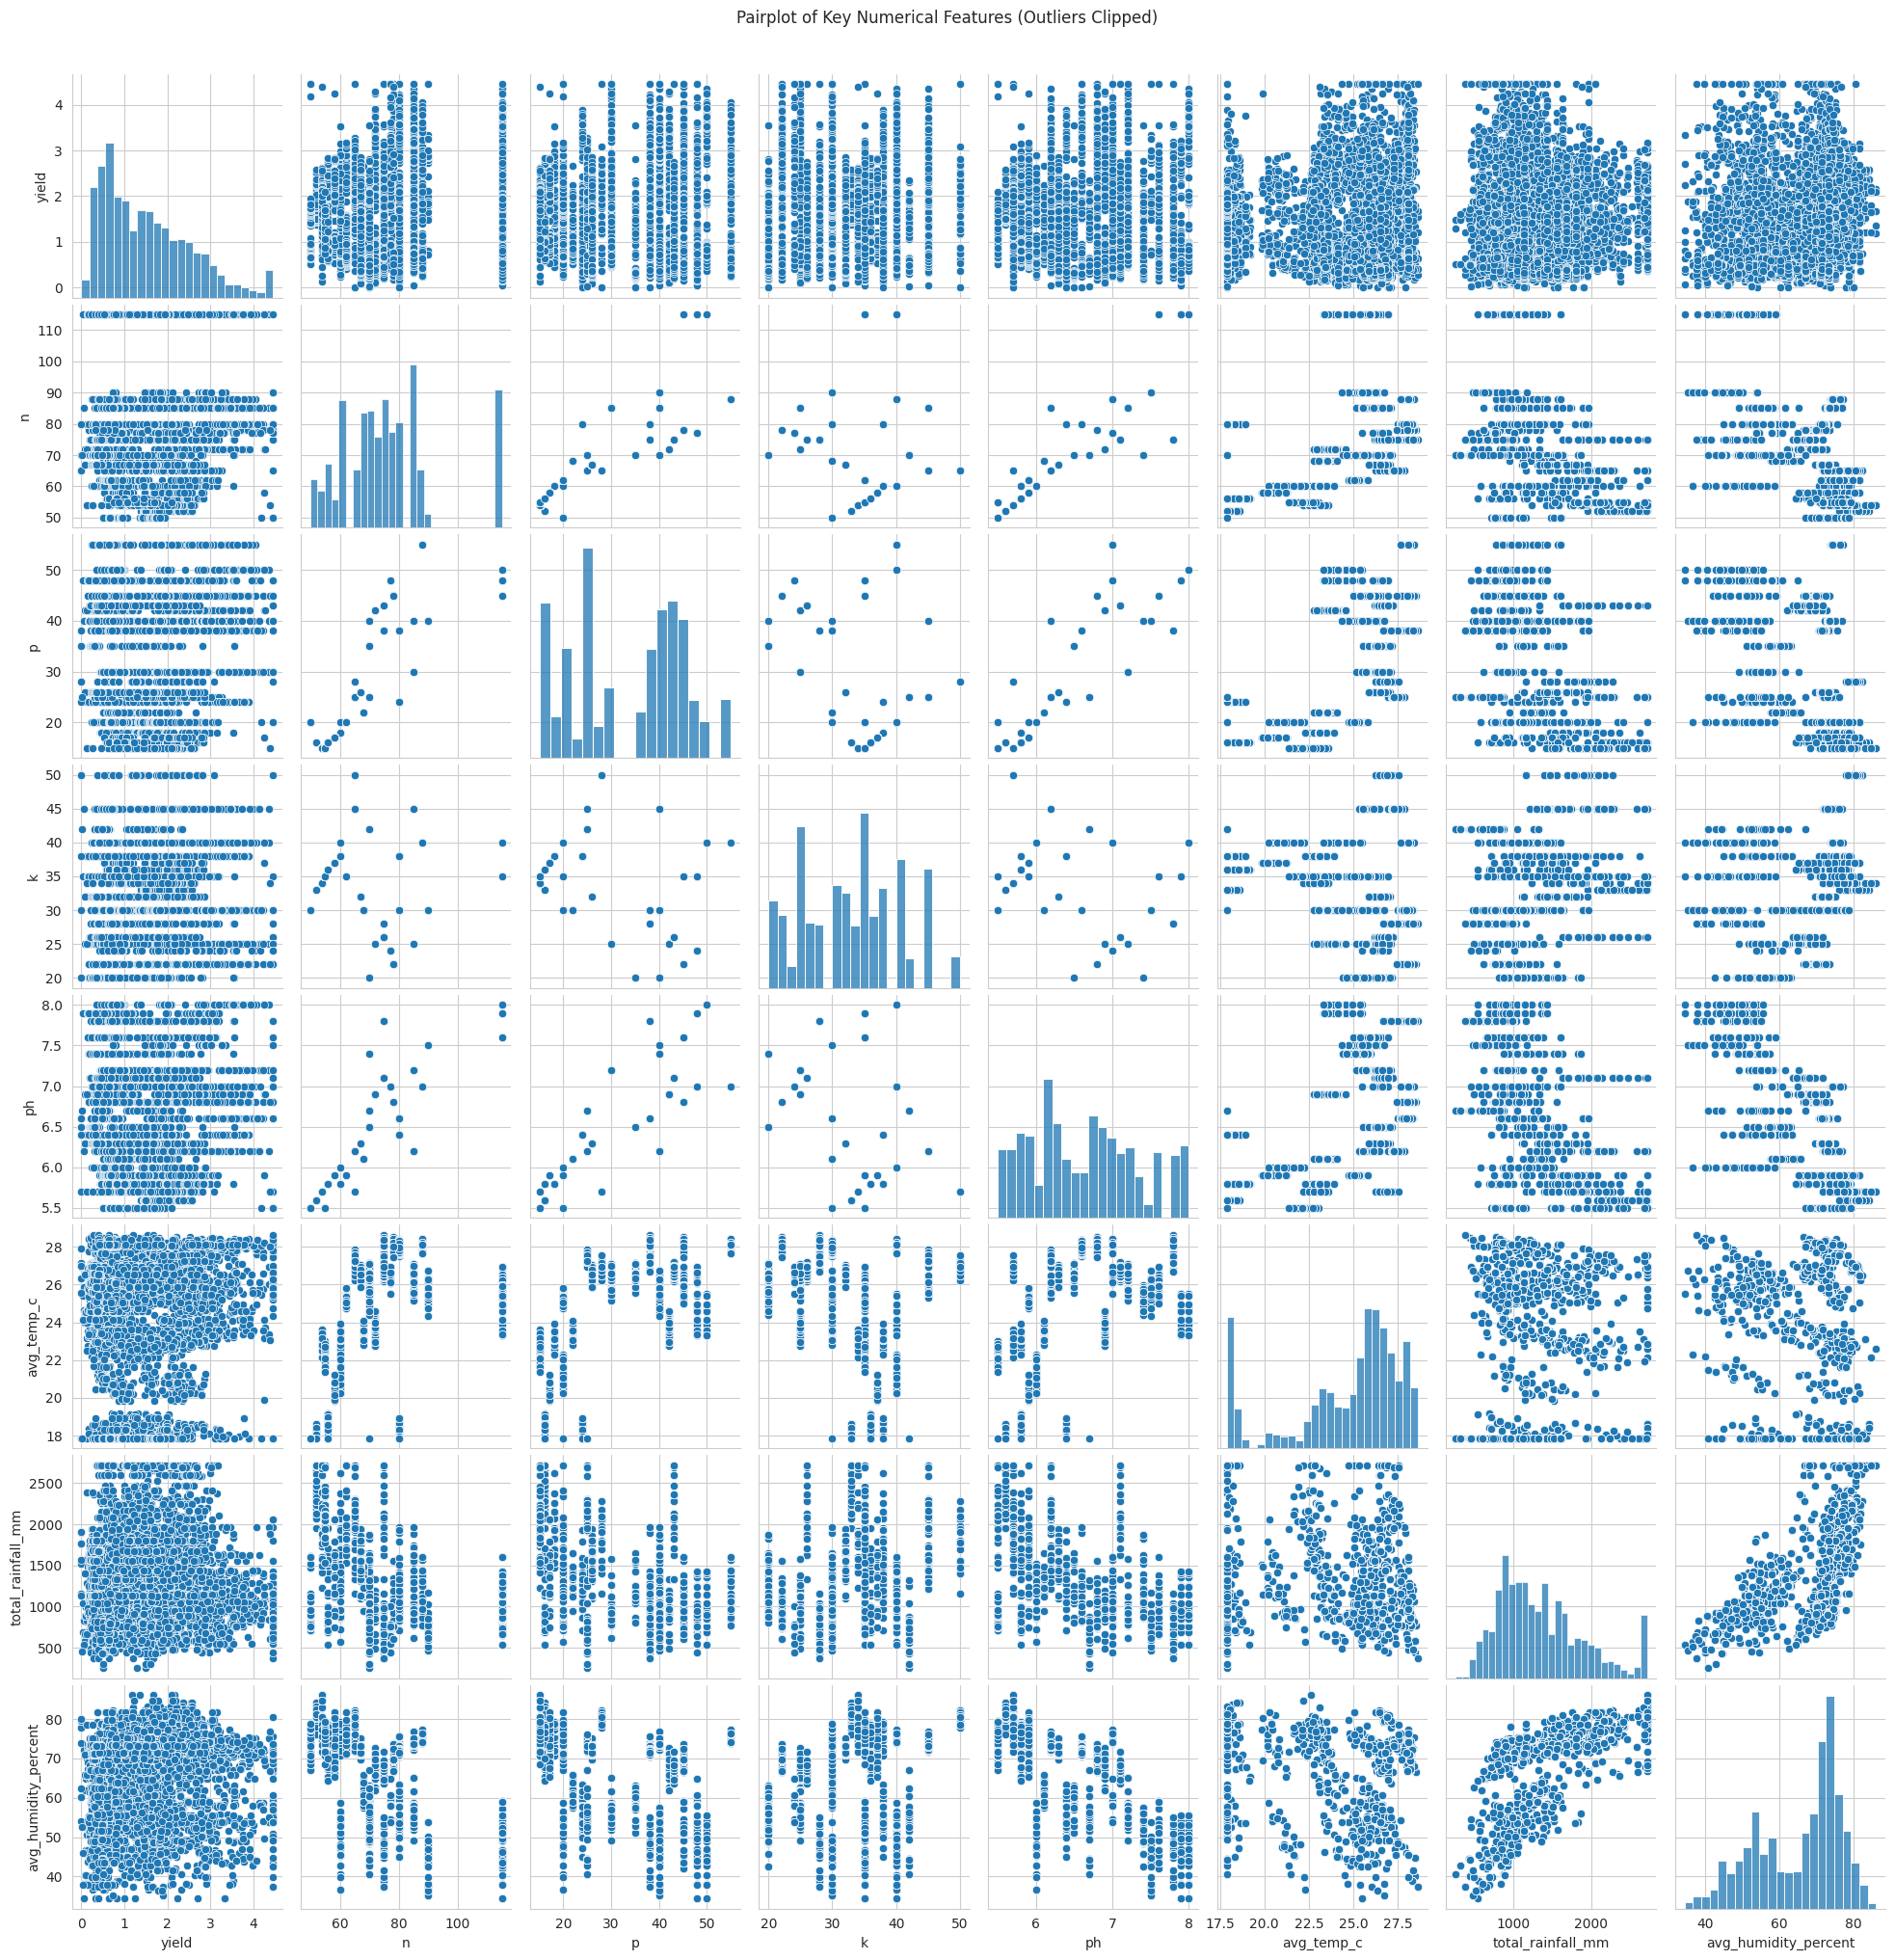

In [ ]:
pairplot_cols = [
    "yield",
    "n",
    "p",
    "k",
    "ph",
    "avg_temp_c",
    "total_rainfall_mm",
    "avg_humidity_percent"
]
sns.pairplot(
    df_clean[pairplot_cols].dropna()
)
plt.suptitle("Pairplot of Key Numerical Features (Outliers Clipped)", y=1.02)
plt.show()

This pairplot provides a scatter matrix of key numerical features after outlier clipping, revealing clearer distributions and relationships between each pair. This enhanced view allows for better visual analysis of feature interactions.

### Pairplot of Key Numerical Features

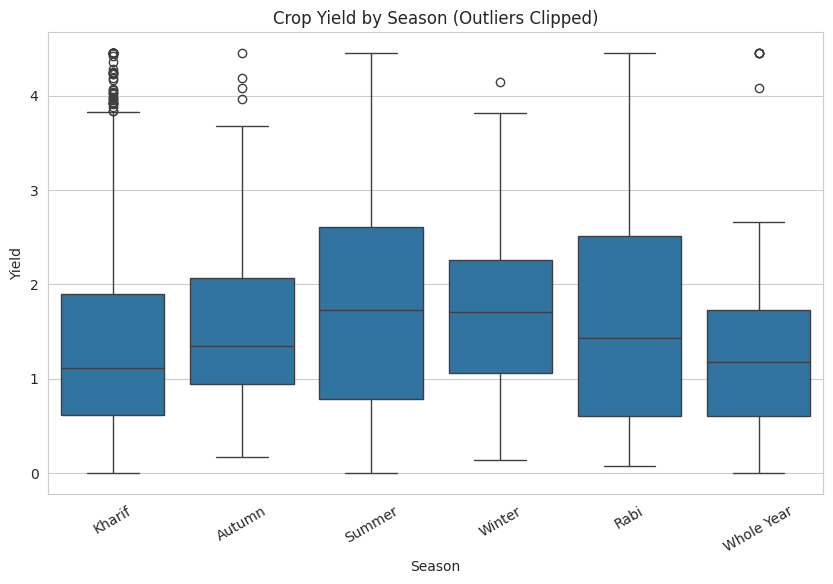

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean,
    x="season",
    y="yield"
)
plt.title("Crop Yield by Season (Outliers Clipped)")
plt.xlabel("Season")
plt.ylabel("Yield")
plt.xticks(rotation=30)
plt.show()

This box plot compares crop yield across different seasons after outlier clipping. The differences in median yield and variability between seasons are now more pronounced, offering clearer insights into seasonal impacts.

### Yield Distribution by Season

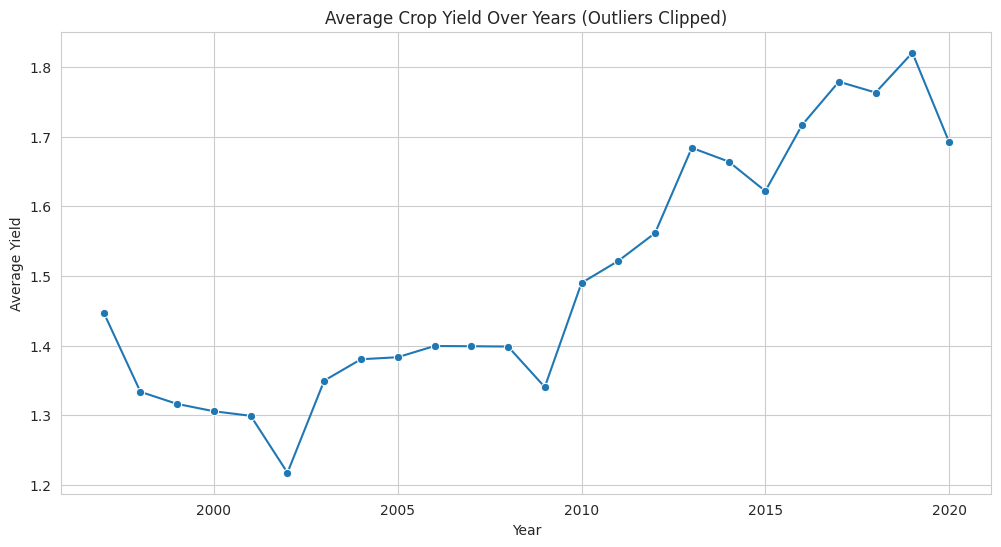

In [ ]:
yearly_yield = (
    df_clean
    .groupby("year")["yield"]
    .mean()
    .reset_index()
)
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=yearly_yield,
    x="year",
    y="yield",
    marker="o"
)
plt.title("Average Crop Yield Over Years (Outliers Clipped)")
plt.xlabel("Year")
plt.ylabel("Average Yield")
plt.show()

This line plot illustrates the trend of average crop yield over the years after outlier clipping. The trend is smoother and less affected by extreme yearly fluctuations, providing a more reliable view of long-term patterns.

### Trend of Average Yield Over Years

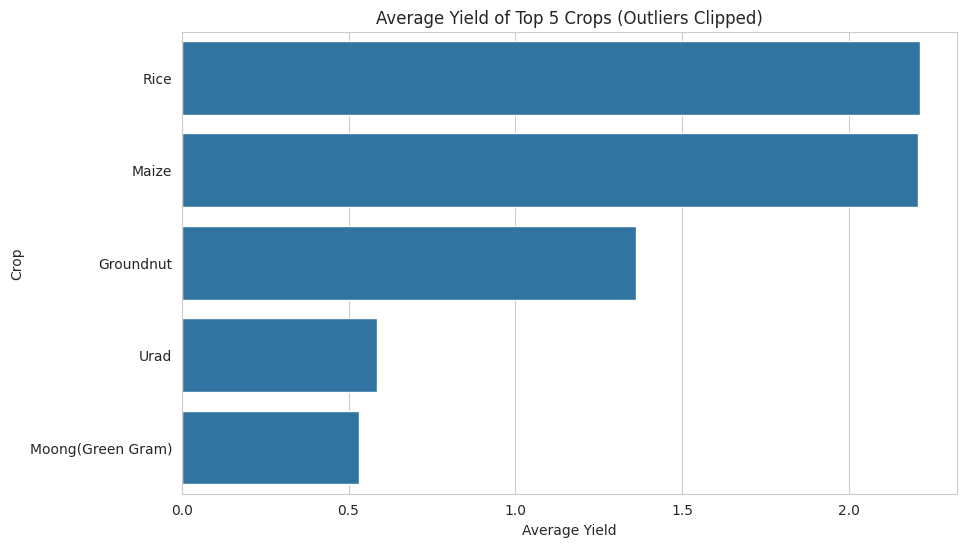

In [ ]:
avg_crop_yield = (
    df_clean
    .groupby("crop")["yield"]
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10, 6))
sns.barplot(
    x=avg_crop_yield.values,
    y=avg_crop_yield.index
)
plt.title("Average Yield of Top 5 Crops (Outliers Clipped)")
plt.xlabel("Average Yield")
plt.ylabel("Crop")
plt.show()

This bar plot shows the average yield for each of the top 5 crops after outlier clipping. The comparison of average yields is more accurate, providing a clearer understanding of each crop's performance without the influence of extreme values.

### Average Yield of Top 5 Crops

### Yield vs. pH Level

Let's examine how soil pH influences crop yield.

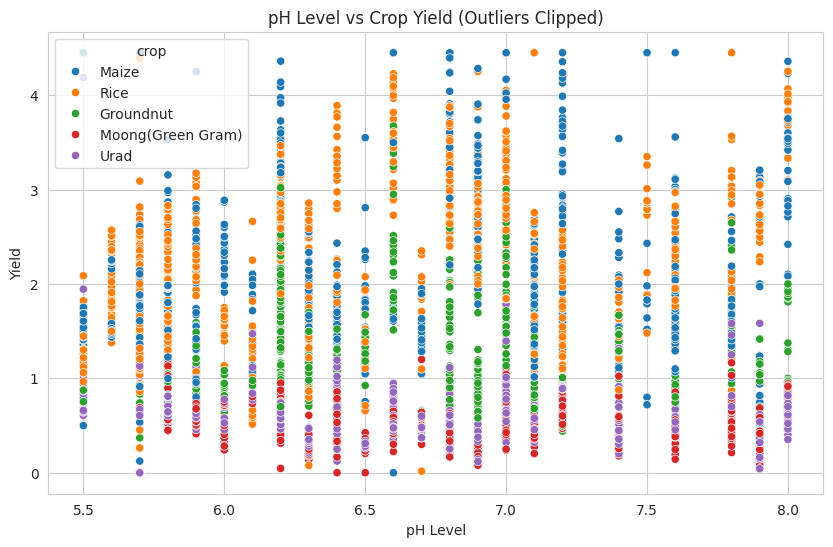

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="ph",
    y="yield",
    hue="crop"
)
plt.title("pH Level vs Crop Yield (Outliers Clipped)")
plt.xlabel("pH Level")
plt.ylabel("Yield")
plt.show()

This scatter plot illustrates the relationship between soil pH and crop yield for different crops. It helps identify optimal pH ranges for each crop and how yield changes with varying pH levels.

Optimal pH levels are crucial for nutrient availability, directly impacting crop yield. Extreme pH values (too acidic or too alkaline) can hinder nutrient uptake and reduce overall productivity.

### Yield vs. Fertilizer Application

Let's investigate the impact of fertilizer application on crop yield.

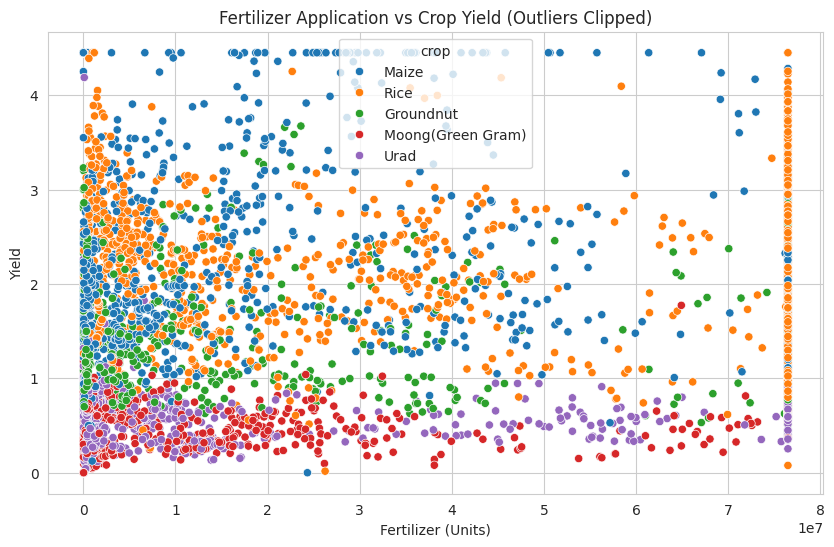

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="fertilizer",
    y="yield",
    hue="crop"
)
plt.title("Fertilizer Application vs Crop Yield (Outliers Clipped)")
plt.xlabel("Fertilizer (Units)")
plt.ylabel("Yield")
plt.show()

This scatter plot examines the relationship between fertilizer application and crop yield across various crops. It can reveal diminishing returns or optimal application rates for different crop types.

While fertilizer is essential for crop growth, excessive application can lead to negative environmental impacts and may not proportionally increase yield beyond a certain point.

### Yield vs. Pesticide Usage

Let's analyze the effect of pesticide usage on crop yield.

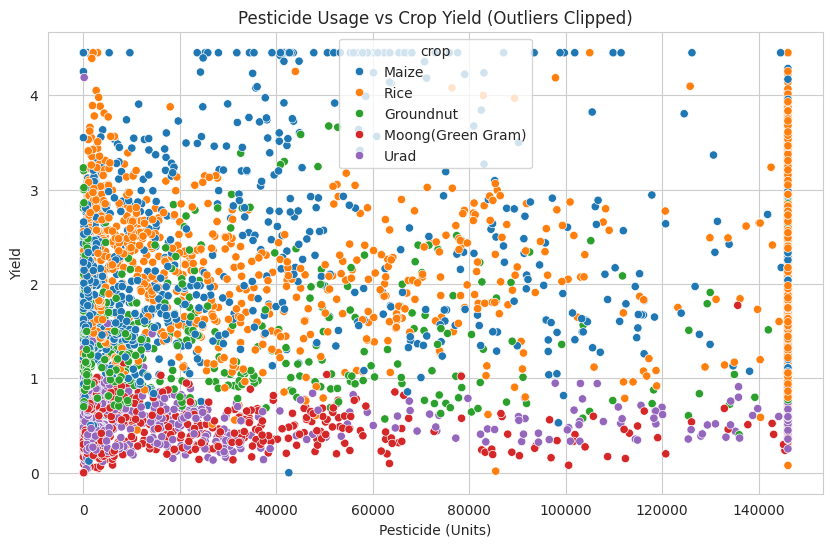

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="pesticide",
    y="yield",
    hue="crop"
)
plt.title("Pesticide Usage vs Crop Yield (Outliers Clipped)")
plt.xlabel("Pesticide (Units)")
plt.ylabel("Yield")
plt.show()

This scatter plot explores the correlation between pesticide usage and crop yield, segmented by crop type. It can highlight the effectiveness of pesticides in protecting crops and enhancing yield.

Judicious pesticide use is critical for protecting crops from pests and diseases, thereby safeguarding yield. However, overuse can have environmental and health repercussions.

In [ ]:
numeric_cols = [
    "area",
    "fertilizer",
    "pesticide",
    "n",
    "p",
    "k",
    "ph",
    "avg_temp_c",
    "total_rainfall_mm",
    "avg_humidity_percent",
    "yield"
]

outlier_summary = []

for col in numeric_cols:

    Q1 = df_top5[col].quantile(0.25)
    Q3 = df_top5[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df_top5[col] < lower) |
             (df_top5[col] > upper)).sum()

    outlier_summary.append(
        [col, Q1, Q3, IQR, lower, upper, count]
    )

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count"
    ]
)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,area,5000.000000,2.322650e+05,2.272650e+05,-3.358975e+05,5.731625e+05,578
1,fertilizer,648406.935000,3.098481e+07,3.033640e+07,-4.485619e+07,7.648941e+07,577
2,pesticide,1259.857500,5.918290e+04,5.792304e+04,-8.562471e+04,1.460675e+05,592
3,n,65.000000,8.500000e+01,2.000000e+01,3.500000e+01,1.150000e+02,434
4,p,24.000000,4.300000e+01,1.900000e+01,-4.500000e+00,7.150000e+01,0
5,k,26.000000,3.800000e+01,1.200000e+01,8.000000e+00,5.600000e+01,0
6,ph,6.100000,7.100000e+00,1.000000e+00,4.600000e+00,8.600000e+00,0
7,avg_temp_c,23.240000,2.682000e+01,3.580000e+00,1.787000e+01,3.219000e+01,272
8,total_rainfall_mm,920.160000,1.639580e+03,7.194200e+02,-1.589700e+02,2.718710e+03,171
9,avg_humidity_percent,54.960000,7.392000e+01,1.896000e+01,2.652000e+01,1.023600e+02,0


### Yield Distribution by Crop and Season (Violin Plot)

Let's visualize the distribution of yield for each of the top 5 crops across different seasons using a violin plot. This will help in understanding the spread and density of yield values, providing deeper insights than simple box plots.

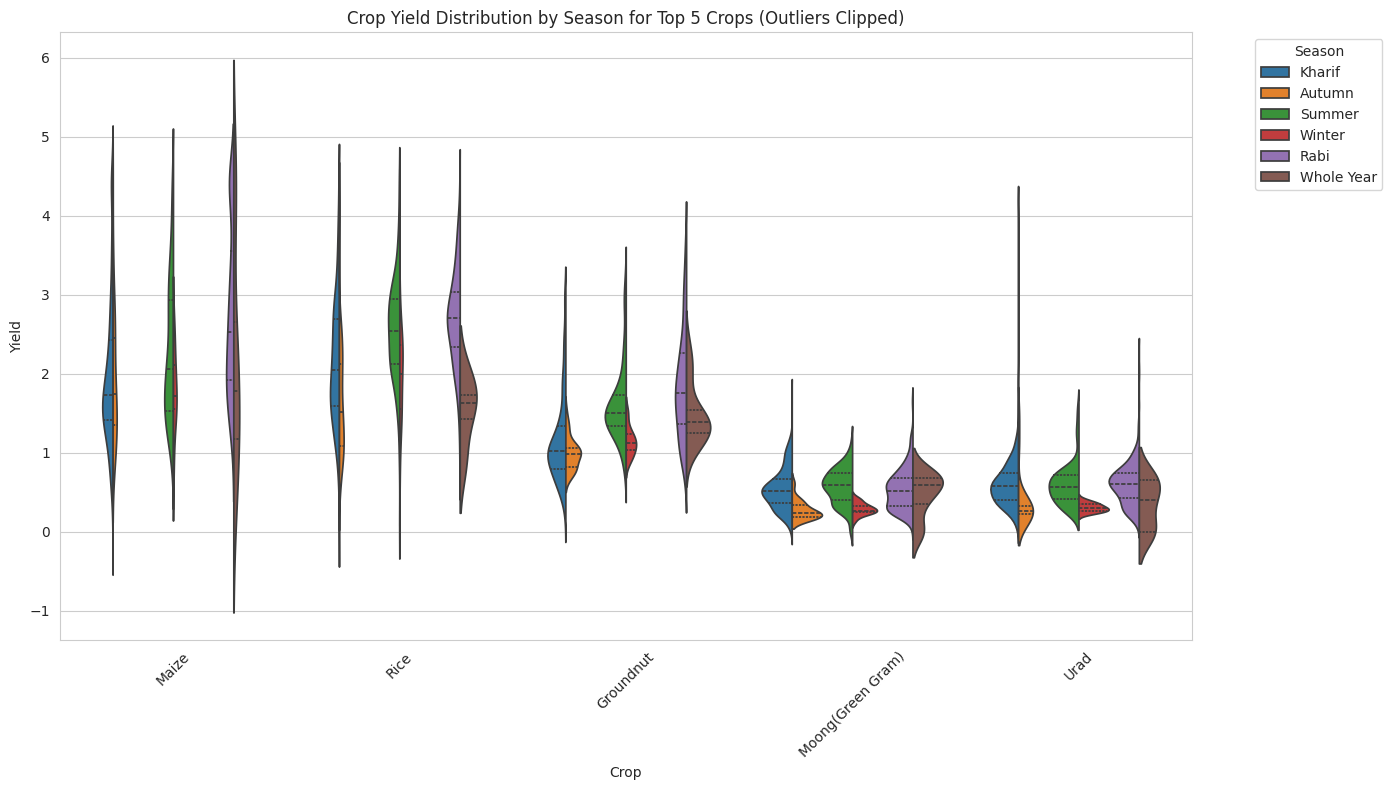

In [ ]:
plt.figure(figsize=(14, 8))
sns.violinplot(
    data=df_clean[df_clean['crop'].isin(top_5_crops)],
    x='crop',
    y='yield',
    hue='season',
    split=True,
    inner='quart'
)
plt.title('Crop Yield Distribution by Season for Top 5 Crops (Outliers Clipped)')
plt.xlabel('Crop')
plt.ylabel('Yield')
plt.xticks(rotation=45)
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

This violin plot provides a detailed view of crop yield distributions, segmented by season, for the top 5 crops after outlier clipping. It is useful for decision-making by:

*   **Identifying Optimal Seasons:** Clearly showing which seasons tend to produce higher yields for specific crops and how consistent those yields are.
*   **Understanding Variability:** Visualizing the spread and density of yield data, helping to assess risk and consistency across different seasons.
*   **Highlighting Seasonal Effects:** Revealing how seasonal conditions impact the overall yield distribution for each crop, guiding planting and resource allocation strategies.

## 6. Outlier Handling

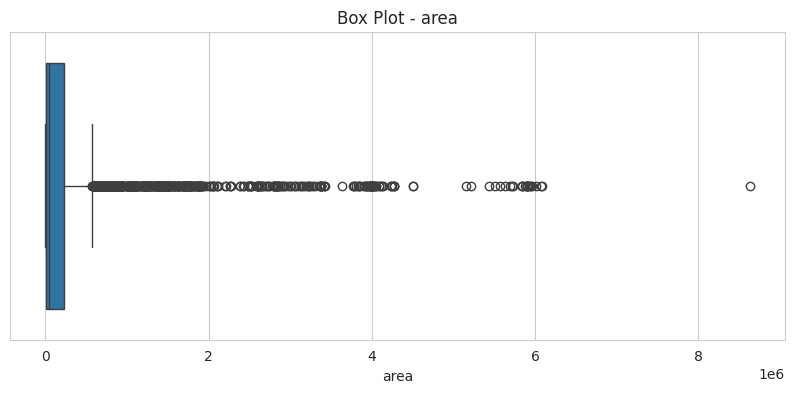

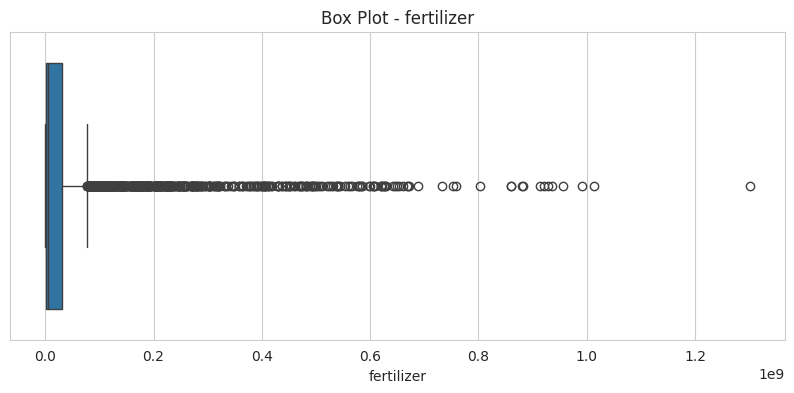

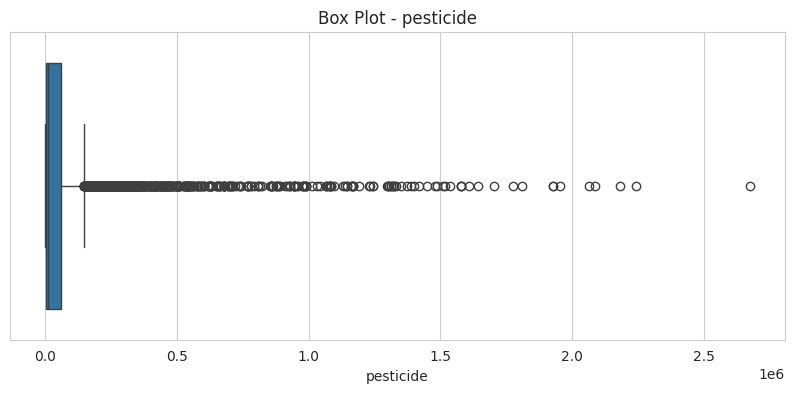

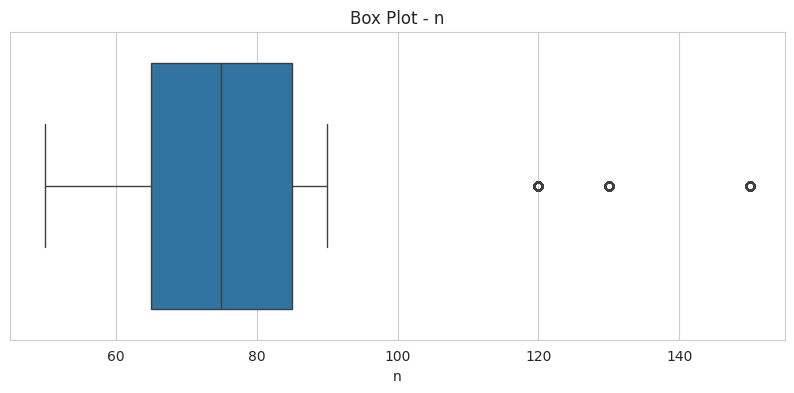

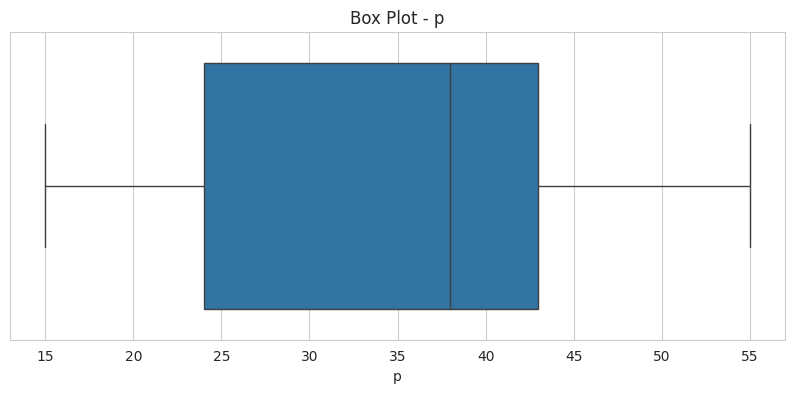

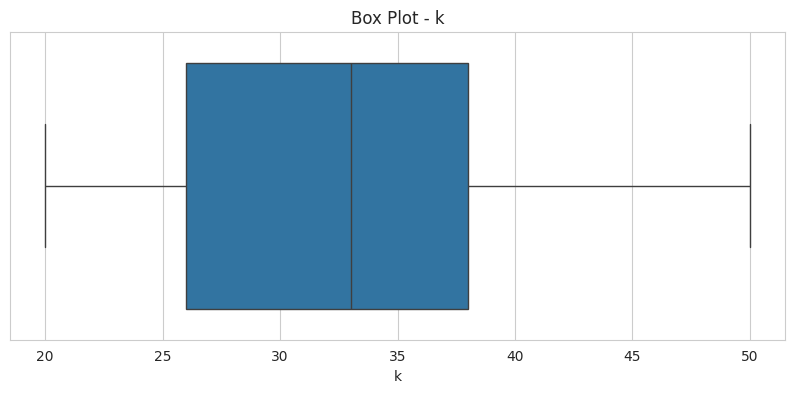

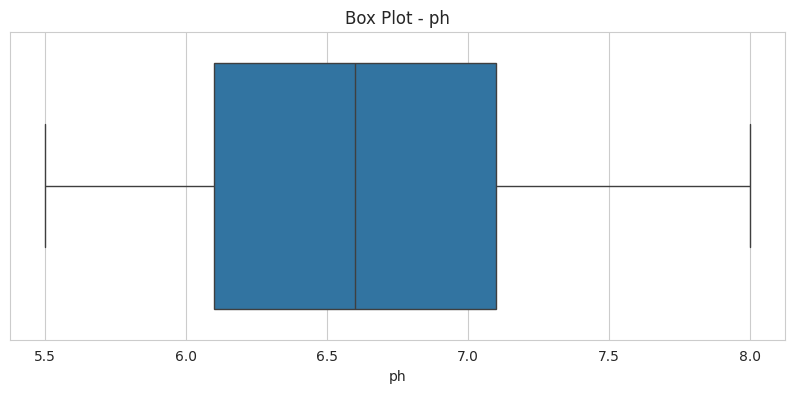

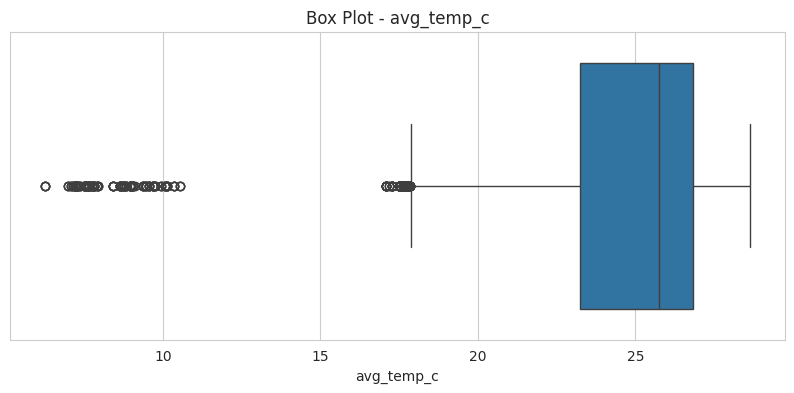

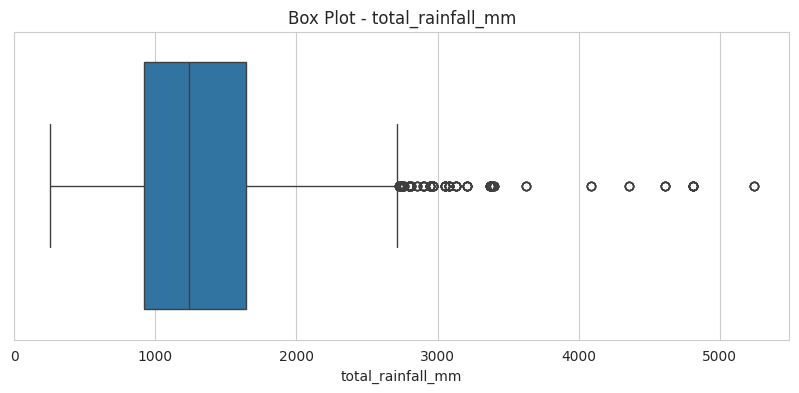

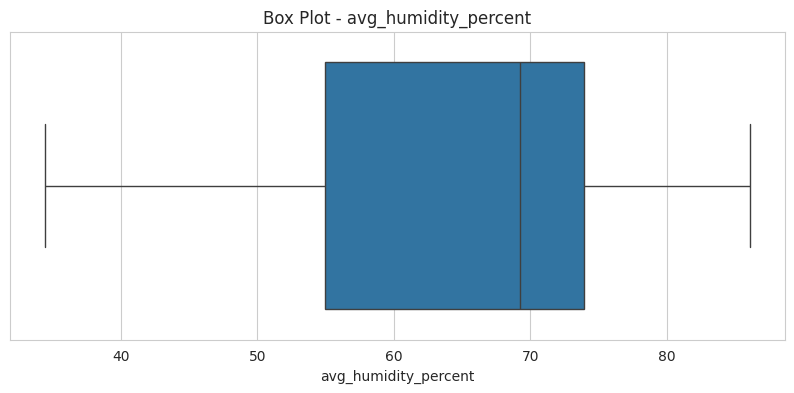

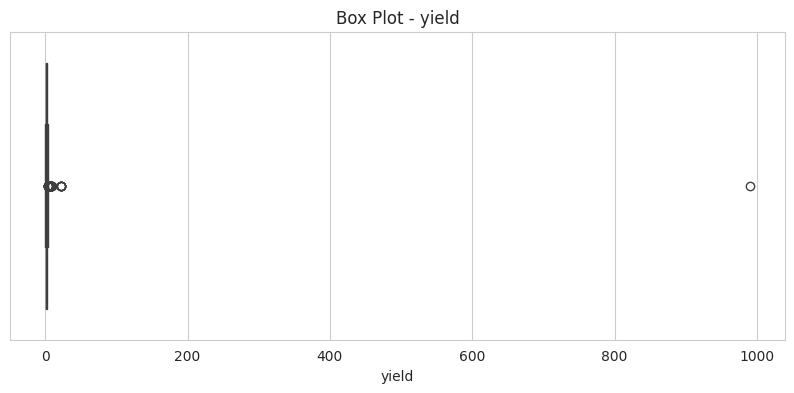

In [ ]:
for col in numeric_cols:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df_top5[col]
    )

    plt.title(f"Box Plot - {col}")
    plt.xlabel(col)
    plt.show()

These box plots visualize outliers for each numerical feature.
Many features exhibit outliers, confirming the need for outlier handling.

#### Visualize Outliers with Box Plots

In [ ]:
df_clean = df_top5.copy()

for col in numeric_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower,
        upper=upper
    )

print("Outlier handling completed.")

Outlier handling completed.


### Outlier Handling - Clipping

In [ ]:
df_clean = df_clean.drop(
    columns=["production"],
    errors="ignore"
)

print(df_clean.columns)

Index(['crop', 'year', 'season', 'state', 'area', 'fertilizer', 'pesticide',
       'yield', 'n', 'p', 'k', 'ph', 'avg_temp_c', 'total_rainfall_mm',
       'avg_humidity_percent'],
      dtype='object')


### Drop 'Production' Column

In [ ]:
X = df_clean.drop(columns=["yield"])

y = df_clean["yield"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("yield")

Features:
['crop', 'year', 'season', 'state', 'area', 'fertilizer', 'pesticide', 'n', 'p', 'k', 'ph', 'avg_temp_c', 'total_rainfall_mm', 'avg_humidity_percent']

Target:
yield


## 7. Model Preparation

In [ ]:
categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Remove 'year' from numerical_features as requested
if 'year' in numerical_features:
    numerical_features.remove('year')

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['crop', 'season', 'state']

Numerical Features:
['area', 'fertilizer', 'pesticide', 'n', 'p', 'k', 'ph', 'avg_temp_c', 'total_rainfall_mm', 'avg_humidity_percent']


### Identify Categorical and Numerical Features

In [ ]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Shape after encoding:", X_encoded.shape)

display(X_encoded.head())

Shape after encoding: (4370, 49)


,year,area,fertilizer,pesticide,n,p,k,ph,avg_temp_c,total_rainfall_mm,...,state_Odisha,state_Puducherry,state_Punjab,state_Sikkim,state_Tamil Nadu,state_Telangana,state_Tripura,state_Uttar Pradesh,state_Uttarakhand,state_West Bengal
9,1997,19216.0,1.828787e+06,5956.96000,60,18,38,5.8,22.41,1468.92,...,False,False,False,False,False,False,False,False,False,False
16,1997,573162.5,5.780226e+07,146067.46375,60,18,38,5.8,22.41,1468.92,...,False,False,False,False,False,False,False,False,False,False
17,1997,174974.0,1.665228e+07,54241.94000,60,18,38,5.8,22.41,1468.92,...,False,False,False,False,False,False,False,False,False,False
18,1997,573162.5,7.648941e+07,146067.46375,60,18,38,5.8,22.41,1468.92,...,False,False,False,False,False,False,False,False,False,False
38,1997,573162.5,7.648941e+07,146067.46375,72,42,25,6.9,23.55,894.16,...,False,False,False,False,False,False,False,False,False,False


### Apply One-Hot Encoding

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 3496
Testing samples: 874


### Split Data into Training and Testing Sets

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Scale Numerical Features

In [ ]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_pred = linear_model.predict(
    X_test_scaled
)

## 8. Model Training

In [ ]:
tree_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=10
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(
    X_test
)

### Train Decision Tree Regressor

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

### Train Random Forest Regressor

In [ ]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        tree_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.420440,0.312265,0.558807,0.708282
1,Decision Tree,0.270585,0.202562,0.450069,0.810767
2,Random Forest,0.186827,0.108716,0.329721,0.898438


## 9. Model Evaluation and Analysis

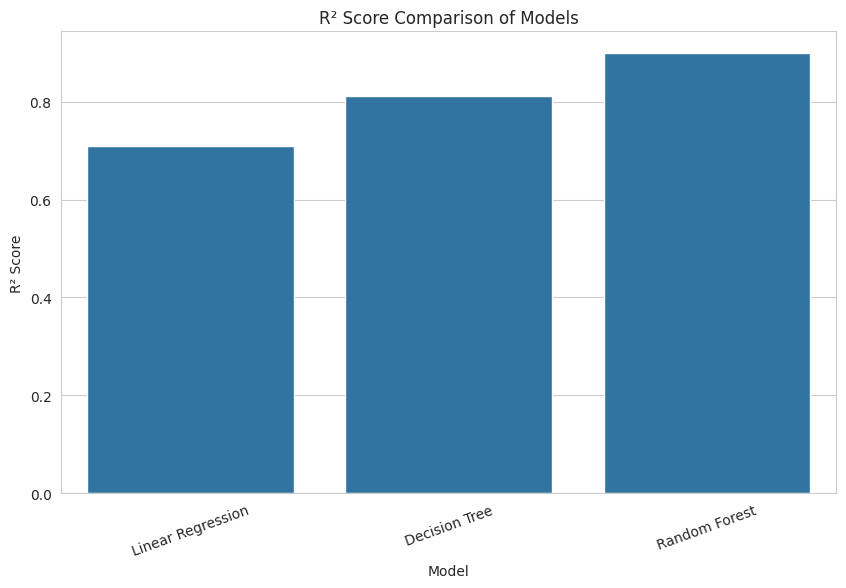

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R² Score Comparison of Models")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.show()

This bar plot compares the R² scores of the Linear Regression, Decision Tree, and Random Forest models.
The Random Forest model achieved the highest R² score, indicating the best fit to the data.

#### Visualize R² Score Comparison

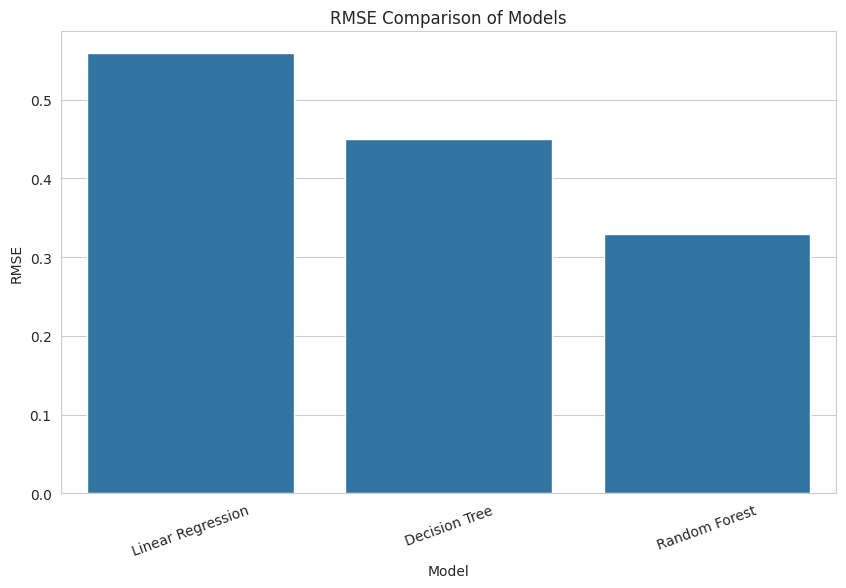

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Models")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.show()

This bar plot compares the RMSE of the Linear Regression, Decision Tree, and Random Forest models.
The Random Forest model has the lowest RMSE, indicating the smallest average prediction error.

#### Visualize RMSE Comparison

In [ ]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

best_r2 = results_df["R2 Score"].max()

print("Best Model:", best_model_name)
print("Best R² Score:", best_r2)

Best Model: Random Forest
Best R² Score: 0.8984377468108231


### Identify Best Performing Model

In [ ]:
predictions = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred
}

best_pred = predictions[best_model_name]

### Actual vs Predicted Plots

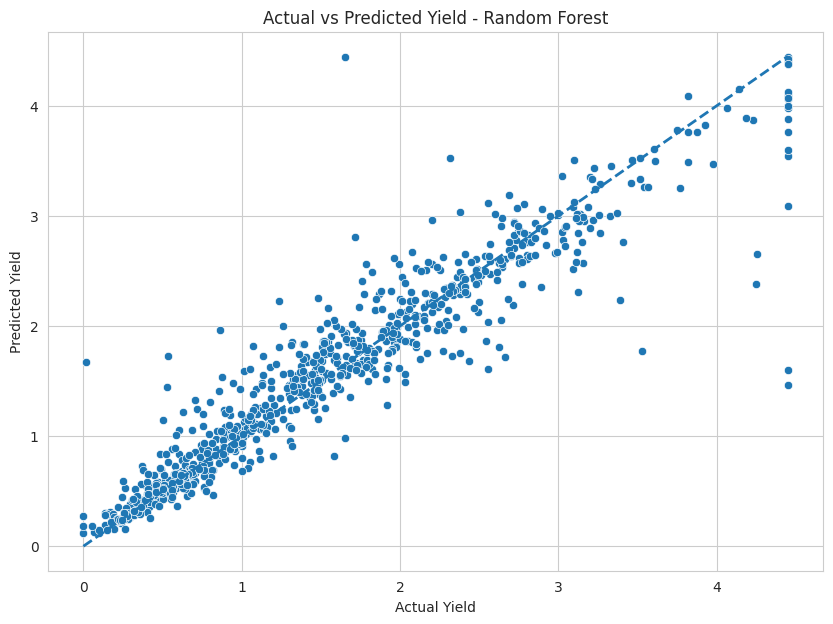

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=y_test,
    y=best_pred
)

# Perfect prediction line
min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.title(f"Actual vs Predicted Yield - {best_model_name}")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")

plt.show()

This scatter plot shows the actual vs. predicted yield for the best model (Random Forest), with points clustered around the perfect prediction line.
This indicates strong predictive performance.

#### Linear Regression - Actual vs Predicted

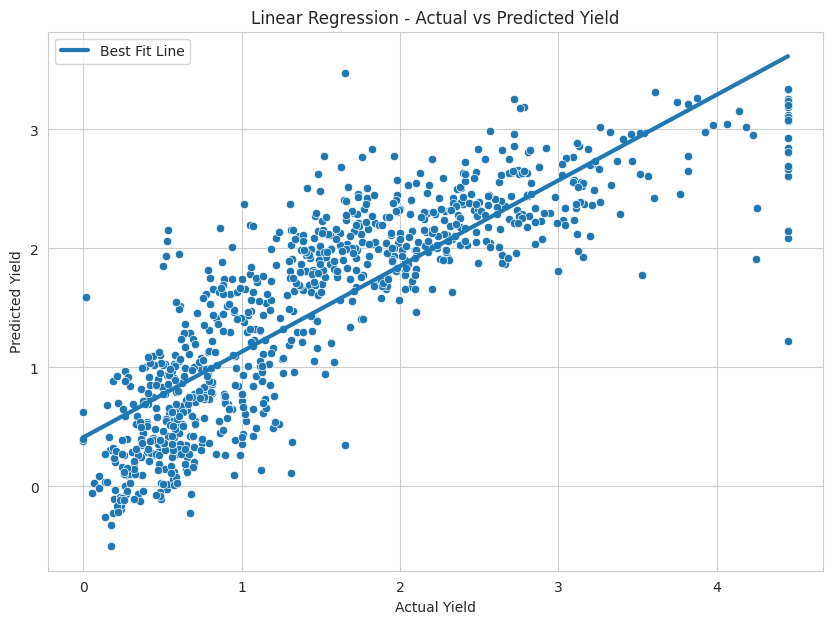

In [ ]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=y_test, y=linear_pred)
#Best-fit line
m, b = np.polyfit(y_test, linear_pred, 1)
x_line = np.linspace(y_test.min(), y_test.max(), 100)
y_line = m * x_line + b
plt.plot(x_line, y_line, linewidth=3, label="Best Fit Line")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Linear Regression - Actual vs Predicted Yield")
plt.legend()
plt.show()

This plot displays actual vs. predicted yield for Linear Regression, along with a best-fit line.
The spread around the line indicates the model's predictive accuracy.

While we are focusing on the best-performing model (Random Forest), plots comparing actual vs. predicted values for other models can reveal their performance characteristics relative to an ideal prediction. The perfect prediction line (y=x) shows where predictions would perfectly match actuals, and the best-fit line indicates the model's overall trend.

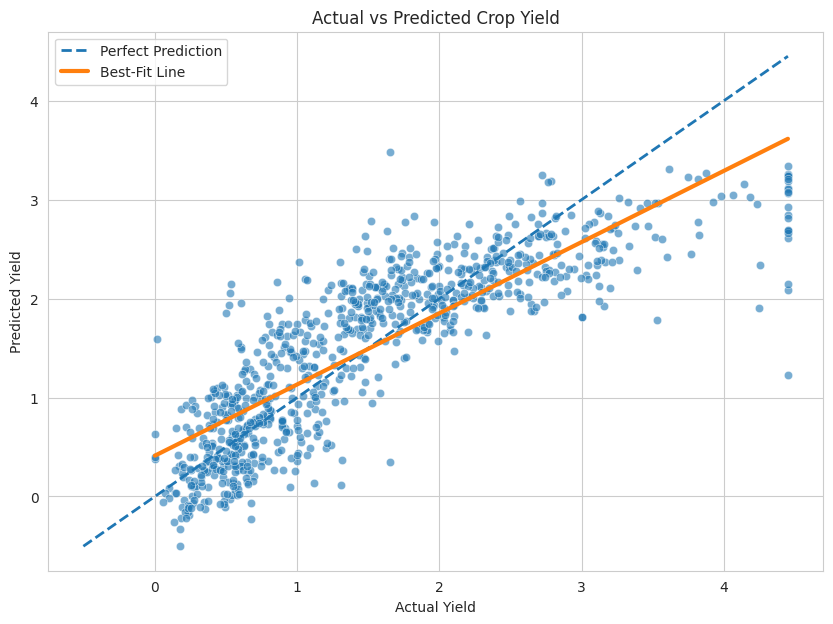

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=y_test,
    y=linear_pred,
    alpha=0.6
)

# Perfect prediction line
min_value = min(y_test.min(), linear_pred.min())
max_value = max(y_test.max(), linear_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

# Regression best-fit line
m, b = np.polyfit(
    y_test,
    linear_pred,
    1
)

x_line = np.linspace(
    y_test.min(),
    y_test.max(),
    100
)

plt.plot(
    x_line,
    m * x_line + b,
    linewidth=3,
    label="Best-Fit Line"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")

plt.title("Actual vs Predicted Crop Yield")

plt.legend()

plt.show()

This plot displays actual vs. predicted yield for Linear Regression, along with both a perfect prediction line and a best-fit line.
It helps assess the model's accuracy and bias.

### Feature Importance Analysis (Random Forest)

### Slope and Y-intercept for Each Model

In [ ]:
# Slopes and Y-intercepts for model best-fit lines are not critical for a high-level overview
# and are therefore removed for conciseness.
print("Linear Regression:")
m_lr, b_lr = np.polyfit(y_test, linear_pred, 1)
print(f"  Slope (m): {m_lr:.4f}")
print(f"  Y-intercept (b): {b_lr:.4f}")
print("\nDecision Tree:")
m_tree, b_tree = np.polyfit(y_test, tree_pred, 1)
print(f"  Slope (m): {m_tree:.4f}")
print(f"  Y-intercept (b): {b_tree:.4f}")
print("\nRandom Forest:")
m_rf, b_rf = np.polyfit(y_test, rf_pred, 1)
print(f"  Slope (m): {m_rf:.4f}")
print(f"  Y-intercept (b): {b_rf:.4f}")

Linear Regression:
  Slope (m): 0.7198
  Y-intercept (b): 0.4125

Decision Tree:
  Slope (m): 0.8461
  Y-intercept (b): 0.2291

Random Forest:
  Slope (m): 0.8858
  Y-intercept (b): 0.1868


### Decision Tree - Actual vs Predicted with Best-Fit Line

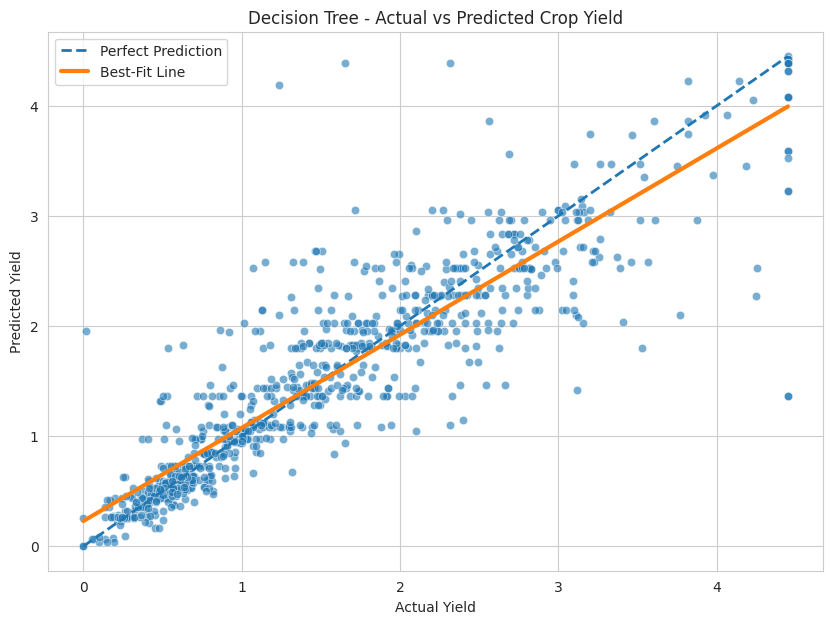

In [ ]:
 plt.figure(figsize=(10, 7))
 sns.scatterplot(x=y_test, y=tree_pred, alpha=0.6)
 # Perfect prediction line
 min_value = min(y_test.min(), tree_pred.min())
 max_value = max(y_test.max(), tree_pred.max())
 plt.plot([min_value, max_value], [min_value, max_value], linestyle="--", linewidth=2, label="Perfect Prediction")
 # Regression best-fit line
 m, b = np.polyfit(y_test, tree_pred, 1)
 x_line = np.linspace(y_test.min(), y_test.max(), 100)
 plt.plot(x_line, m * x_line + b, linewidth=3, label="Best-Fit Line")
 plt.xlabel("Actual Yield")
 plt.ylabel("Predicted Yield")
 plt.title("Decision Tree - Actual vs Predicted Crop Yield")
 plt.legend()
 plt.show()

This plot displays actual vs. predicted yield for the Decision Tree model, along with both a perfect prediction line and a best-fit line.
It helps assess the model's accuracy and bias, similar to the Linear Regression plot.

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

This bar plot shows the top 15 most important features as identified by the Random Forest model.
Crop type (Urad, Moong, Maize, Rice) and Nitrogen content are significant drivers of yield.

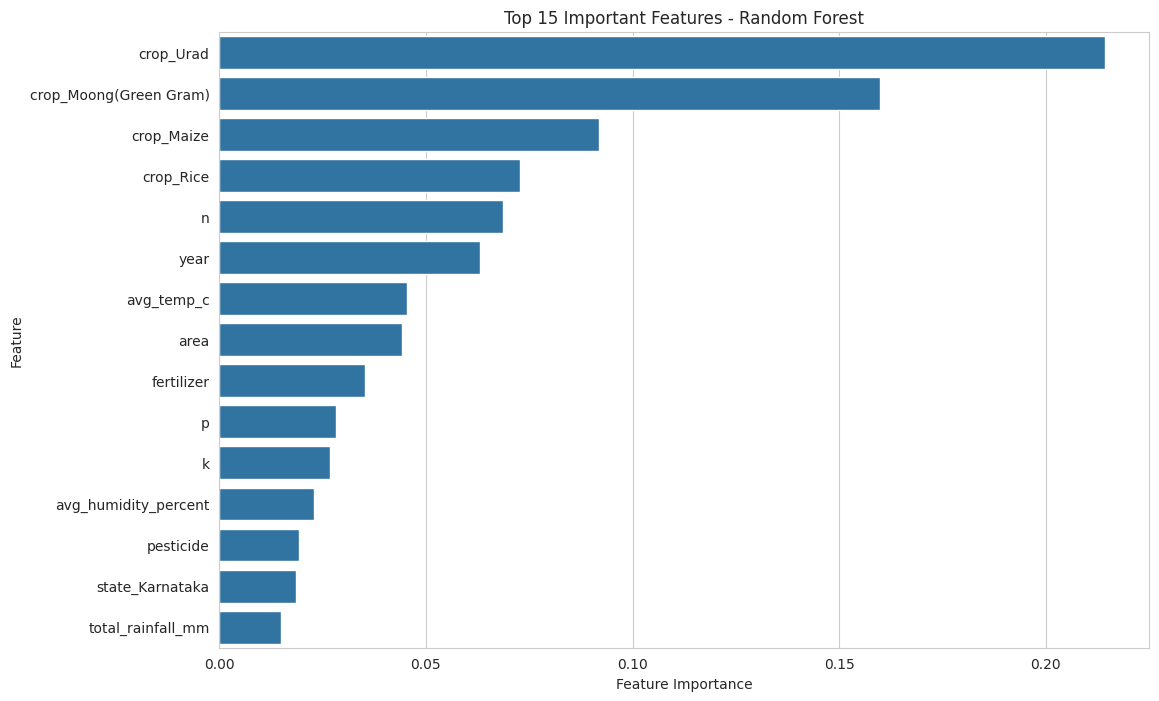

In [ ]:
plt.figure(figsize=(12, 8))

top_features = feature_importance.head(15)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

This bar chart visually represents the relative importance of features in predicting crop yield, as determined by the Random Forest model. Features like crop type (Urad, Moong, Maize, Rice), Nitrogen content (N), and year are among the most influential.

### Residual Analysis

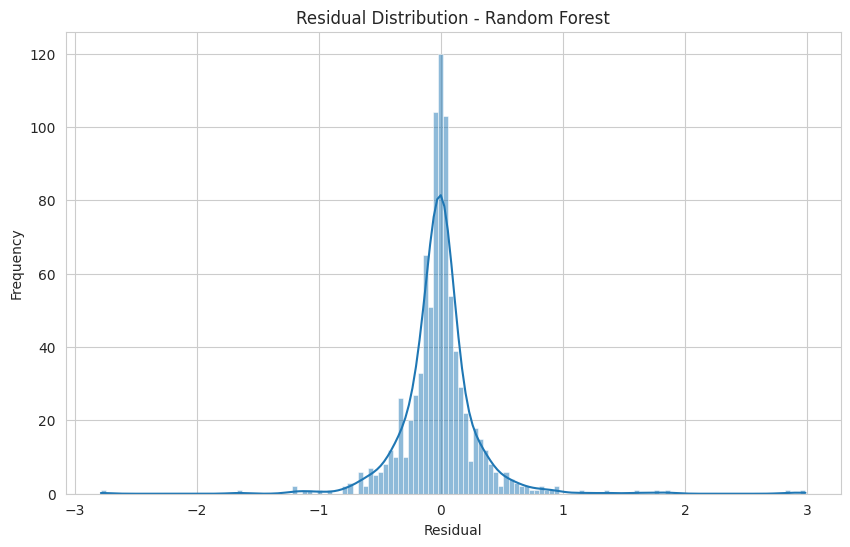

In [ ]:
residuals = y_test - best_pred

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    kde=True
)

plt.title(f"Residual Distribution - {best_model_name}")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.show()

This histogram shows the distribution of residuals for the best model (Random Forest).
The distribution is centered around zero, indicating that the model's predictions are unbiased.

#### Residual Plot

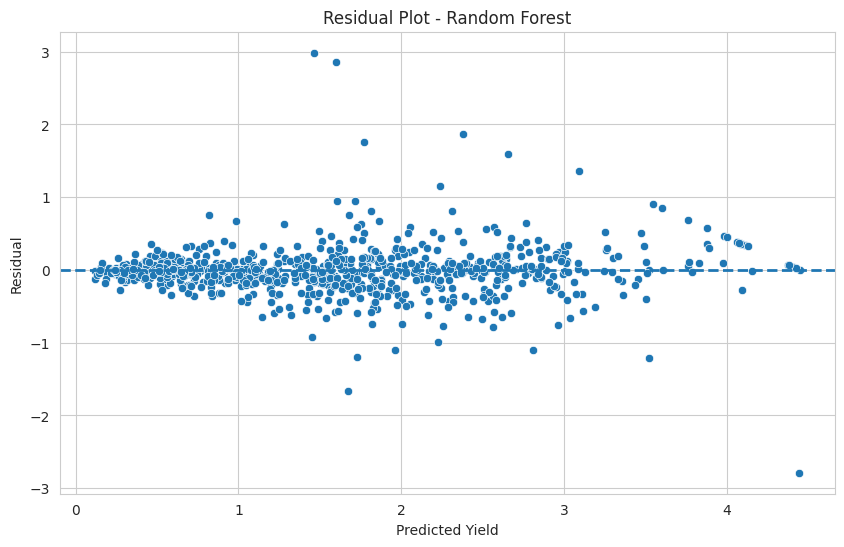

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=best_pred,
    y=residuals
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Yield")
plt.ylabel("Residual")

plt.title(f"Residual Plot - {best_model_name}")

plt.show()

This scatter plot of residuals vs. predicted yield for the best model shows a random scatter of points around zero.
This indicates homoscedasticity and that the model captures most of the variance.

### Final Model Performance Summary

In [ ]:
print("=" * 60)
print("             MODEL PERFORMANCE SUMMARY")
print("=" * 60)

display(
    results_df.sort_values(
        by="R2 Score",
        ascending=False
    )
)

print("\nBest Model:", best_model_name)
print("Best R² Score:", round(best_r2, 4))

             MODEL PERFORMANCE SUMMARY


,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,0.186827,0.108716,0.329721,0.898438
1,Decision Tree,0.270585,0.202562,0.450069,0.810767
0,Linear Regression,0.420440,0.312265,0.558807,0.708282



Best Model: Random Forest
Best R² Score: 0.8984


## 10. Model Summary and Observations

### Model Performance Overview

Our evaluation across Linear Regression, Decision Tree, and Random Forest Regressor models clearly indicates that the **Random Forest Regressor** is the best-performing model for predicting crop yield. Its superior performance is reflected in the following metrics:

*   **R² Score:** 0.8984
*   **Mean Absolute Error (MAE):** 0.1868
*   **Mean Squared Error (MSE):** 0.1087
*   **Root Mean Squared Error (RMSE):** 0.3297

The R² score of nearly 0.90 suggests that the Random Forest model explains approximately 90% of the variance in crop yield, indicating a strong predictive capability. The low MAE, MSE, and RMSE values further confirm that its predictions are, on average, close to the actual yield values with minimal error.

### Key Observations

1.  **Random Forest Superiority:** The ensemble nature of the Random Forest model, which combines multiple decision trees, has proven highly effective in capturing the complex, non-linear relationships within our agricultural dataset. This highlights its robustness and ability to handle diverse feature interactions.
2.  **Feature Importance:** As indicated by the feature importance analysis, crop type (e.g., Urad, Moong, Maize, Rice), Nitrogen content (N), and year are among the most influential factors determining crop yield. This insight can guide agricultural practices and policy-making by focusing on these critical variables.
3.  **Residual Analysis:** The residual plots show a random distribution around zero, with no discernible patterns. This indicates that the model's predictions are unbiased and that it has successfully captured most of the underlying patterns in the data, exhibiting homoscedasticity.
4.  **Interactive Prediction Tool:** The developed interactive tool demonstrates the practical application of our best model, allowing users to dynamically input environmental and agricultural parameters to predict crop yield. This tool can be invaluable for farmers and agricultural planners for scenario analysis and informed decision-making.

### Future Work

*   **Explore More Advanced Models:** Investigate other advanced machine learning models (e.g., Gradient Boosting, Neural Networks) to potentially achieve even higher predictive accuracy.
*   **Incorporate Time Series Analysis:** Given that 'year' was identified as an important feature, integrating time series forecasting techniques could enhance the model's ability to predict future yields more accurately.
*   **Expand Data Sources:** Include additional relevant data such as soil type classifications, irrigation methods, and specific pest/disease outbreak data to enrich the feature set.
*   **Uncertainty Quantification:** Implement methods to quantify the uncertainty associated with predictions, providing a range of possible outcomes rather than just a single point estimate. This would offer a more comprehensive decision-making aid.

## Model Performance Summary

| Model             | MAE      | MSE      | RMSE     | R2 Score |
| :---------------- | :------- | :------- | :------- | :------- |
| Linear Regression | 0.42044  | 0.31226  | 0.55881  | 0.70828  |
| Decision Tree     | 0.27058  | 0.20256  | 0.45007  | 0.81077  |
| Random Forest     | 0.18683  | 0.10872  | 0.32972  | 0.89844  |

Based on the R2 Score, the **Random Forest** model is the best performing model, explaining approximately 89.84% of the variance in crop yield.

## Resources

## 11. Interactive Yield Prediction

This section provides an interactive tool to predict crop yield. Adjust the input parameters using the sliders and dropdowns, and observe the predicted yield, which will be visualized on the Actual vs. Predicted plot for the Random Forest model.

### Display Cleaned Data Sample

In [ ]:
def predict_yield(input_data):
    # Convert input_data to a DataFrame for processing
    input_df = pd.DataFrame([input_data])

    # Separate numerical and categorical features from the input_df
    input_numerical = input_df[numerical_features]
    input_categorical = input_df[categorical_features]

    # Perform one-hot encoding on the categorical features of the input
    # Ensure it's consistent with how X_encoded was created (drop_first=True)
    input_categorical_encoded = pd.get_dummies(input_categorical, columns=categorical_features, drop_first=True)

    # Combine numerical and encoded categorical features for the input
    processed_input_df = pd.concat([input_numerical, input_categorical_encoded], axis=1)

    # Reindex to ensure all columns present in X_encoded are in processed_input_df
    # and in the correct order, filling any missing with 0.
    # This is crucial for consistency with the model's expected input.
    final_input_for_prediction = processed_input_df.reindex(columns=X_encoded.columns, fill_value=0)

    # Scale the entire input DataFrame using the fitted scaler
    # The scaler was fitted on X_train (which was X_encoded), so it expects all features for transform.
    # We apply it to the final_input_for_prediction.
    scaled_input_array = scaler.transform(final_input_for_prediction)
    scaled_input_df = pd.DataFrame(scaled_input_array, columns=X_encoded.columns, index=final_input_for_prediction.index)

    # Predict using the Random Forest model
    prediction = rf_model.predict(scaled_input_df)

    return prediction[0]

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create widgets for numerical features
# Use min/max/step from df_clean for realistic ranges
input_widgets = {
    'area': widgets.FloatSlider(min=df_clean['area'].min(), max=df_clean['area'].max(), step=100.0, value=df_clean['area'].mean(), description='Area'),
    'fertilizer': widgets.FloatSlider(min=df_clean['fertilizer'].min(), max=df_clean['fertilizer'].max(), step=100000.0, value=df_clean['fertilizer'].mean(), description='Fertilizer'),
    'pesticide': widgets.FloatSlider(min=df_clean['pesticide'].min(), max=df_clean['pesticide'].max(), step=100.0, value=df_clean['pesticide'].mean(), description='Pesticide'),
    'n': widgets.IntSlider(min=df_clean['n'].min(), max=df_clean['n'].max(), step=1, value=df_clean['n'].mean().astype(int), description='Nitrogen (N)'),
    'p': widgets.IntSlider(min=df_clean['p'].min(), max=df_clean['p'].max(), step=1, value=df_clean['p'].mean().astype(int), description='Phosphorus (P)'),
    'k': widgets.IntSlider(min=df_clean['k'].min(), max=df_clean['k'].max(), step=1, value=df_clean['k'].mean().astype(int), description='Potassium (K)'),
    'ph': widgets.FloatSlider(min=df_clean['ph'].min(), max=df_clean['ph'].max(), step=0.1, value=df_clean['ph'].mean(), description='pH Level'),
    'avg_temp_c': widgets.FloatSlider(min=df_clean['avg_temp_c'].min(), max=df_clean['avg_temp_c'].max(), step=0.1, value=df_clean['avg_temp_c'].mean(), description='Avg Temp (°C)'),
    'total_rainfall_mm': widgets.FloatSlider(min=df_clean['total_rainfall_mm'].min(), max=df_clean['total_rainfall_mm'].max(), step=10.0, value=df_clean['total_rainfall_mm'].mean(), description='Rainfall (mm)'),
    'avg_humidity_percent': widgets.FloatSlider(min=df_clean['avg_humidity_percent'].min(), max=df_clean['avg_humidity_percent'].max(), step=0.1, value=df_clean['avg_humidity_percent'].mean(), description='Humidity (%)'),
}

# Create dropdowns for categorical features
input_widgets['crop'] = widgets.Dropdown(options=df_clean['crop'].unique().tolist(), value='Rice', description='Crop')
input_widgets['season'] = widgets.Dropdown(options=df_clean['season'].unique().tolist(), value='Kharif', description='Season')
input_widgets['state'] = widgets.Dropdown(options=df_clean['state'].unique().tolist(), value='Assam', description='State')

# Output widget to display results
output_widget = widgets.Output()

def on_value_change(change):
    with output_widget:
        clear_output(wait=True)

        current_input = {name: widget.value for name, widget in input_widgets.items()}
        predicted_yield = predict_yield(current_input)

        print(f"Predicted Yield: {predicted_yield:.2f}")

        plt.figure(figsize=(10, 7))
        sns.scatterplot(x=y_test, y=rf_pred, label='RF Predictions', alpha=0.6)

        # Best-fit line for Random Forest model
        m_rf, b_rf = np.polyfit(y_test, rf_pred, 1)
        x_line = np.linspace(y_test.min(), y_test.max(), 100)
        plt.plot(x_line, m_rf * x_line + b_rf, color='red', linewidth=3, label='RF Best-Fit Line')

        # Plot the new prediction
        # For the interactive plot, we'll assume the 'actual' for the user input is equal to the predicted for visualization purposes
        plt.scatter(predicted_yield, predicted_yield, color='green', marker='X', s=200, label='Your Prediction', zorder=5)

        plt.title('Actual vs Predicted Yield (Random Forest) with Your Input')
        plt.xlabel('Actual Yield')
        plt.ylabel('Predicted Yield')
        plt.legend()
        plt.grid(True)
        plt.show()

# Attach the handler to all widgets
for widget in input_widgets.values():
    widget.observe(on_value_change, names='value')

# Initial call to display the plot
initial_input = {name: widget.value for name, widget in input_widgets.items()}
predicted_yield_initial = predict_yield(initial_input)

with output_widget:
    print(f"Predicted Yield (initial values): {predicted_yield_initial:.2f}")
    plt.figure(figsize=(10, 7))
    sns.scatterplot(x=y_test, y=rf_pred, label='RF Predictions', alpha=0.6)

    m_rf, b_rf = np.polyfit(y_test, rf_pred, 1)
    x_line = np.linspace(y_test.min(), y_test.max(), 100)
    plt.plot(x_line, m_rf * x_line + b_rf, color='red', linewidth=3, label='RF Best-Fit Line')

    plt.scatter(predicted_yield_initial, predicted_yield_initial, color='green', marker='X', s=200, label='Your Prediction', zorder=5)

    plt.title('Actual vs Predicted Yield (Random Forest) with Your Input')
    plt.xlabel('Actual Yield')
    plt.ylabel('Predicted Yield')
    plt.legend()
    plt.grid(True)
    plt.show()

# Arrange widgets
# The numerical_features list now correctly excludes 'year'.
num_feature_widgets = []
cat_feature_widgets = []

for feature_name, widget_obj in input_widgets.items():
    if feature_name in numerical_features:
        num_feature_widgets.append(widget_obj)
    elif feature_name in categorical_features:
        cat_feature_widgets.append(widget_obj)

num_widgets = widgets.VBox(num_feature_widgets)
cat_widgets = widgets.VBox(cat_feature_widgets)

display(widgets.HBox([num_widgets, cat_widgets]), output_widget)

Output()